In [ ]:
%pip install -q yfinance lxml

In [ ]:
import pandas as pd
import yfinance as yf
import requests

from io import StringIO
from datetime import datetime, timezone
from pathlib import Path

print("Python libraries loaded successfully.")

Python libraries loaded successfully.


In [ ]:
DATA_DIR = Path("/content/CRM_CWK1/data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Data folder created:", DATA_DIR)

Data folder created: /content/CRM_CWK1/data


In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Download the S&P 500 company list
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)
response.raise_for_status()

tables = pd.read_html(StringIO(response.text))
companies = tables[0][
    ["Symbol", "Security", "GICS Sector"]
].copy()

# Adjust ticker symbols for Yahoo Finance
companies["YahooTicker"] = (
    companies["Symbol"].str.replace(".", "-", regex=False)
)

# Record the download date
retrieval_date = datetime.now(timezone.utc).isoformat()
companies["RetrievalDateUTC"] = retrieval_date

# Save the company list
companies.to_csv(
    DATA_DIR / "sp500_tickers.csv",
    index=False
)

print("Number of shares:", len(companies))
print("Retrieved at:", retrieval_date)
display(companies.head(10))

Number of shares: 503
Retrieved at: 2026-11-23T09:40:52.419119+00:00


,Symbol,Security,GICS Sector,YahooTicker,RetrievalDateUTC
0,MMM,3M,Industrials,MMM,2026-11-23T09:40:52.419119+00:00
1,AOS,A. O. Smith,Industrials,AOS,2026-11-23T09:40:52.419119+00:00
2,ABT,Abbott Laboratories,Health Care,ABT,2026-11-23T09:40:52.419119+00:00
3,ABBV,AbbVie,Health Care,ABBV,2026-11-23T09:40:52.419119+00:00
4,ACN,Accenture,Information Technology,ACN,2026-11-23T09:40:52.419119+00:00
5,ADBE,Adobe Inc.,Information Technology,ADBE,2026-11-23T09:40:52.419119+00:00
6,AMD,Advanced Micro Devices,Information Technology,AMD,2026-11-23T09:40:52.419119+00:00
7,AES,AES Corporation,Utilities,AES,2026-11-23T09:40:52.419119+00:00
8,AFL,Aflac,Financials,AFL,2026-11-23T09:40:52.419119+00:00
9,A,Agilent Technologies,Health Care,A,2026-11-23T09:40:52.419119+00:00


In [ ]:
start_date = "2021-01-01"
end_date = "2025-01-01"

# Small test using two shares and the market index
test_tickers = ["AAPL", "MSFT", "^GSPC"]

test_data = yf.download(
    test_tickers,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

print("Number of rows:", len(test_data))
print("Fields:", test_data.columns)
print("First date:", test_data.index.min())
print("Last date:", test_data.index.max())

display(test_data.head())

test_data.to_csv(
    DATA_DIR / "market_data_test.csv"
)

Number of rows: 1005
Fields: MultiIndex([('Adj Close',  'AAPL'),
            ('Adj Close',  'MSFT'),
            ('Adj Close', '^GSPC'),
            (    'Close',  'AAPL'),
            (    'Close',  'MSFT'),
            (    'Close', '^GSPC'),
            (     'High',  'AAPL'),
            (     'High',  'MSFT'),
            (     'High', '^GSPC'),
            (      'Low',  'AAPL'),
            (      'Low',  'MSFT'),
            (      'Low', '^GSPC'),
            (     'Open',  'AAPL'),
            (     'Open',  'MSFT'),
            (     'Open', '^GSPC'),
            (   'Volume',  'AAPL'),
            (   'Volume',  'MSFT'),
            (   'Volume', '^GSPC')],
           names=['Price', 'Ticker'])
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


Price        Adj Close                                Close              \
Ticker            AAPL        MSFT        ^GSPC        AAPL        MSFT   
Date                                                                      
2021-01-04  125.537109  207.165161  3700.649902  129.410004  217.690002   
2021-01-05  127.089226  207.365021  3726.860107  131.009995  217.899994   
2021-01-06  122.811218  201.988205  3748.139893  126.599998  212.250000   
2021-01-07  127.001953  207.736160  3803.790039  130.919998  218.289993   
2021-01-08  128.098068  209.001877  3824.679932  132.050003  219.619995   

Price                          High                                  Low  \
Ticker            ^GSPC        AAPL        MSFT        ^GSPC        AAPL   
Date                                                                       
2021-01-04  3700.649902  133.610001  223.000000  3769.989990  126.760002   
2021-01-05  3726.860107  131.740005  218.520004  3737.830078  128.429993   
2021-01-06  3748.139893  131.050003  216.490005  3783.040039  126.379997   
2021-01-07  3803.790039  131.630005  219.339996  3811.550049  127.860001   
2021-01-08  3824.679932  132.630005  220.580002  3826.689941  130.229996   

Price                                      Open                           \
Ticker            MSFT        ^GSPC        AAPL        MSFT        ^GSPC   
Date                                                                       
2021-01-04  214.809998  3662.709961  133.520004  222.529999  3764.610107   
2021-01-05  215.699997  3695.070068  128.889999  217.259995  3698.020020   
2021-01-06  211.940002  3705.340088  127.720001  212.169998  3712.199951   
2021-01-07  213.710007  3764.709961  128.360001  214.039993  3764.709961   
2021-01-08  217.029999  3783.600098  132.429993  218.679993  3815.050049   

Price          Volume                        
Ticker           AAPL      MSFT       ^GSPC  
Date                                         
2021-01-04  143301900  37130100  5015000000  
2021-01-05   97664900  23823000  4591020000  
2021-01-06  155088000  35930700  6064110000  
2021-01-07  109578200  27694500  5099160000  
2021-01-08  105158200  22956200  4773040000

In [ ]:
# Extract the S&P 500 benchmark from our test data
benchmark = test_data.xs(
    "^GSPC",
    axis=1,
    level="Ticker"
)

benchmark.to_csv(DATA_DIR / "sp500_benchmark.csv")

print("Benchmark rows:", len(benchmark))
display(benchmark.head())

Benchmark rows: 1005


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-01-04,3700.649902,3700.649902,3769.989990,3662.709961,3764.610107,5015000000
2021-01-05,3726.860107,3726.860107,3737.830078,3695.070068,3698.020020,4591020000
2021-01-06,3748.139893,3748.139893,3783.040039,3705.340088,3712.199951,6064110000
2021-01-07,3803.790039,3803.790039,3811.550049,3764.709961,3764.709961,5099160000
2021-01-08,3824.679932,3824.679932,3826.689941,3783.600098,3815.050049,4773040000


In [ ]:
import time

tickers = companies["YahooTicker"].dropna().unique().tolist()
batch_size = 25
download_log = []

for start in range(0, len(tickers), batch_size):
    batch_number = start // batch_size + 1
    batch = tickers[start:start + batch_size]

    print("Downloading batch", batch_number)

    try:
        data = yf.download(
            batch,
            start=start_date,
            end=end_date,
            auto_adjust=False,
            actions=True,
            group_by="ticker",
            progress=False,
            threads=False,
            timeout=30
        )

        share_tables = []

        for ticker in batch:
            if ticker not in data.columns.get_level_values(0):
                download_log.append([ticker, "Missing"])
                continue

            share = data[ticker].copy()

            if "Close" not in share or share["Close"].notna().sum() == 0:
                download_log.append([ticker, "No data"])
                continue

            share = share.reset_index()
            share["Ticker"] = ticker
            share_tables.append(share)

            download_log.append([ticker, "Downloaded"])

        if share_tables:
            batch_data = pd.concat(share_tables, ignore_index=True)
            batch_data.to_csv(
                DATA_DIR / f"daily_batch_{batch_number:02d}.csv.gz",
                index=False,
                compression="gzip"
            )

    except Exception as e:
        print("Batch error:", e)
        for ticker in batch:
            download_log.append([ticker, "Batch error"])

    time.sleep(2)

# Save the download log
download_log = pd.DataFrame(
    download_log,
    columns=["Ticker", "Status"]
)

download_log.to_csv(
    DATA_DIR / "download_log.csv",
    index=False
)

print("\nDownload summary:")
print(download_log["Status"].value_counts())

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')



Download summary:
Status
Downloaded    498
No data         5
Name: count, dtype: int64


In [ ]:
batch_files = sorted(DATA_DIR.glob("daily_batch_*.csv.gz"))

daily_data = pd.concat(
    [pd.read_csv(file) for file in batch_files],
    ignore_index=True
)

daily_data.to_csv(
    DATA_DIR / "sp500_daily_data.csv.gz",
    index=False,
    compression="gzip"
)

print("Total records:", len(daily_data))
print("Unique shares:", daily_data["Ticker"].nunique())
print("Available columns:", daily_data.columns.tolist())

display(daily_data.head())

Total records: 500490
Unique shares: 498
Available columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits', 'Ticker']


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,146.321075,147.324417,142.600327,143.704010,117.366669,3583455.0,0.0,0.0,MMM
1,2021-01-05,143.821075,144.857864,142.683945,143.461533,117.168625,2745179.0,0.0,0.0,MMM
2,2021-01-06,144.414719,146.797653,143.846161,145.643814,118.950981,4002294.0,0.0,0.0,MMM
3,2021-01-07,143.444809,145.033447,138.929764,141.906357,115.898499,7012626.0,0.0,0.0,MMM
4,2021-01-08,141.446487,141.755859,137.633774,139.314377,113.781548,5750488.0,0.0,0.0,MMM


In [ ]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/CRM_CWK1_backup",
    "zip",
    "/content/CRM_CWK1"
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 1.2 — Data Validation and Alignment

In [ ]:
# Identify tickers that failed
failed_tickers = download_log.loc[
    download_log["Status"] != "Downloaded", "Ticker"
].tolist()

print("Tickers failed and need to investigate:")
print(failed_tickers)

Tickers failed and need to investigate:
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [ ]:
retry_results = []

for ticker in failed_tickers:
    print("Retrying:", ticker)

    try:
        retry_data = yf.download(
            ticker,
            start=start_date,
            end=end_date,
            auto_adjust=False,
            progress=False,
            threads=False
        )

        if isinstance(retry_data.columns, pd.MultiIndex):
            retry_data = retry_data.xs(
                ticker, axis=1, level="Ticker"
            )

        valid_rows = retry_data["Close"].notna().sum()

        retry_results.append({
            "Ticker": ticker,
            "Valid price rows": int(valid_rows)
        })

        if valid_rows > 0:
            retry_data = retry_data.reset_index()
            retry_data["Ticker"] = ticker

            retry_data.to_csv(
                DATA_DIR / f"retry_{ticker}.csv.gz",
                index=False,
                compression="gzip"
            )

    except Exception as error:
        print("Retry failed:", error)
        retry_results.append({
            "Ticker": ticker,
            "Valid price rows": 0
        })

display(pd.DataFrame(retry_results))

Retrying: FDXF


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Retrying: HONA


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Retrying: Q


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Retrying: SNDK


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Retrying: VYLR


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


,Ticker,Valid price rows
0,FDXF,0
1,HONA,0
2,Q,0
3,SNDK,0
4,VYLR,0


In [ ]:
# Convert dates to proper date values
daily_data["Date"] = pd.to_datetime(daily_data["Date"])

# Create a summary for each share
audit = daily_data.groupby("Ticker").agg(
    Total_Rows=("Date", "size"),
    Close_Count=("Close", "count"),
    Adj_Close_Count=("Adj Close", "count"),
    Volume_Count=("Volume", "count")
)

# Identify missing observations
audit["Missing_Prices"] = (
    audit["Total_Rows"] - audit["Adj_Close_Count"]
)

audit["Missing_Volume"] = (
    audit["Total_Rows"] - audit["Volume_Count"]
)

print("Shares checked:", len(audit))
print("Shares with missing adjusted prices:",
      (audit["Missing_Prices"] > 0).sum())

print("Shares with missing volume:",
      (audit["Missing_Volume"] > 0).sum())

display(
    audit.sort_values(
        "Missing_Prices", ascending=False
    ).head(15)
)


Shares checked: 498
Shares with missing adjusted prices: 10
Shares with missing volume: 10


,Total_Rows,Close_Count,Adj_Close_Count,Volume_Count,Missing_Prices,Missing_Volume
Ticker,,,,,,
GEV,1005,193,193,193,812,812
SOLV,1005,194,194,194,811,811
RDDT,1005,197,197,197,808,808
VLTO,1005,313,313,313,692,692
GEHC,1005,513,513,513,492,492
CEG,1005,742,742,742,263,263
HOOD,1005,862,862,862,143,143
APP,1005,935,935,935,70,70
COIN,1005,936,936,936,69,69


In [ ]:
# Check for duplicates ticker-date combinations
duplicates = daily_data.duplicated(
    subset=["Ticker", "Date"]
).sum()

# Check invalid values
bad_close = (daily_data["Close"] <= 0).sum()
bad_adjusted = (daily_data["Adj Close"] <= 0).sum()
negative_volume = (daily_data["Volume"] < 0).sum()
zero_volume = (daily_data["Volume"] == 0).sum()

# Check corporate actions
dividend_days = (daily_data["Dividends"] > 0).sum()
split_days = (daily_data["Stock Splits"] > 0).sum()

print("Duplicate ticker-date records:", duplicates)
print("Nonpositive Close prices:", bad_close)
print("Nonpositive adjusted prices:", bad_adjusted)
print("Negative volume records:", negative_volume)
print("Zero volume records:", zero_volume)
print("Dividend records:", dividend_days)
print("Stock split records:", split_days)

Duplicate ticker-date records: 0
Nonpositive Close prices: 0
Nonpositive adjusted prices: 0
Negative volume records: 0
Zero volume records: 451
Dividend records: 6086
Stock split records: 61


### 1.2.1 Historical Data Coverage

In [ ]:
# Examining the first and last valid dates for each share
history_results = []

for ticker, share in daily_data.groupby("Ticker"):
    share = share.sort_values("Date")

    # Dates with usable price and volume data
    valid = (
        share["Close"].notna()
        & share["Adj Close"].notna()
        & share["Volume"].notna()
    )

    valid_dates = share.loc[valid, "Date"]

    if valid_dates.empty:
        continue

    first_date = valid_dates.min()
    last_date = valid_dates.max()

    # Check for missing data between the first and last dates
    inside = share["Date"].between(first_date, last_date)
    internal_gaps = (inside & ~valid).sum()

    history_results.append({
        "Ticker": ticker,
        "First_Date": first_date.date(),
        "Last_Date": last_date.date(),
        "Valid_Days": valid.sum(),
        "Internal_Gaps": internal_gaps,
        "Zero_Volume_Days": (
            (share["Volume"] == 0) & valid
        ).sum()
    })

history_audit = pd.DataFrame(history_results)

# Show shares with fewer than 1005 valid days
incomplete = history_audit[
    history_audit["Valid_Days"] < 1005
]

display(incomplete.sort_values("Valid_Days"))

# Save the validation evidence
history_audit.to_csv(
    DATA_DIR / "history_validation.csv",
    index=False
)


,Ticker,First_Date,Last_Date,Valid_Days,Internal_Gaps,Zero_Volume_Days
201,GEV,2024-03-27,2024-12-31,193,0,0
407,SOLV,2024-03-26,2024-12-31,194,0,0
382,RDDT,2024-03-21,2024-12-31,197,0,0
463,VLTO,2023-10-04,2024-12-31,313,0,0
199,GEHC,2022-12-15,2024-12-31,513,0,0
84,CEG,2022-01-19,2024-12-31,742,0,0
224,HOOD,2021-07-29,2024-12-31,862,0,0
39,APP,2021-04-15,2024-12-31,935,0,0
104,COIN,2021-04-14,2024-12-31,936,0,0
171,EXE,2021-02-10,2024-12-31,979,0,0


### 1.2.2 Trading Volume Validation

In [ ]:
# Find shares with zero reported trading volume
zero_volume = daily_data[
    (daily_data["Volume"] == 0)
    & daily_data["Close"].notna()
]

print("Zero-volume records:", len(zero_volume))

# Count zero-volume days for each share
zero_summary = (
    zero_volume.groupby("Ticker")
    .size()
    .sort_values(ascending=False)
)

print("Shares affected:", len(zero_summary))

display(zero_summary.head(15))

# Show example records
display(
    zero_volume[
        ["Ticker", "Date", "Close", "Volume"]
    ].head(15)
)

zero_volume.to_csv(
    DATA_DIR / "zero_volume_review.csv",
    index=False
)

Zero-volume records: 451
Shares affected: 2


,0
Ticker,
SW,424
FERG,27


,Ticker,Date,Close,Volume
192963,FERG,2021-01-07,121.300003,0.0
192964,FERG,2021-01-08,121.300003,0.0
192966,FERG,2021-01-12,124.199997,0.0
192967,FERG,2021-01-13,124.199997,0.0
192968,FERG,2021-01-14,124.199997,0.0
192969,FERG,2021-01-15,124.199997,0.0
192971,FERG,2021-01-20,123.000000,0.0
192972,FERG,2021-01-21,123.000000,0.0
192973,FERG,2021-01-22,123.000000,0.0
192974,FERG,2021-01-25,123.000000,0.0


### 1.2.3 Share Eligibility and Exclusion Log

In [ ]:
# Use the benchmark's trading dates as the common calendar
required_dates = set(pd.to_datetime(benchmark.index))

# Group the data by ticker
share_groups = dict(tuple(daily_data.groupby("Ticker")))

selection_results = []

for ticker in companies["YahooTicker"]:
    share = share_groups.get(ticker)

    if share is None:
        status = "Excluded"
        reason = "No historical data available"

    elif (
        len(share) != len(required_dates)
        or set(share["Date"]) != required_dates
        or share[["Close", "Adj Close", "Volume"]].isna().any().any()
    ):
        status = "Excluded"
        reason = "Incomplete historical coverage"

    elif (
        (share["Close"] <= 0).any()
        or (share["Adj Close"] <= 0).any()
        or (share["Volume"] < 0).any()
    ):
        status = "Excluded"
        reason = "Invalid price or negative volume"

    elif (share["Volume"] == 0).any():
        status = "Excluded"
        reason = "Zero-volume observations"

    else:
        status = "Included"
        reason = "Passed validation"

    selection_results.append({
        "Ticker": ticker,
        "Status": status,
        "Reason": reason
    })

selection_log = pd.DataFrame(selection_results)

print("Selection summary:")
print(selection_log["Status"].value_counts())

print("\nExclusion reasons:")
print(selection_log["Reason"].value_counts())

display(selection_log[
    selection_log["Status"] == "Excluded"
])

selection_log.to_csv(
    DATA_DIR / "share_selection_log.csv",
    index=False
)

Selection summary:
Status
Included    486
Excluded     17
Name: count, dtype: int64

Exclusion reasons:
Reason
Passed validation                 486
Incomplete historical coverage     10
No historical data available        5
Zero-volume observations            2
Name: count, dtype: int64


,Ticker,Status,Reason
40,APP,Excluded,Incomplete historical coverage
116,COIN,Excluded,Incomplete historical coverage
123,CEG,Excluded,Incomplete historical coverage
181,EXE,Excluded,Incomplete historical coverage
192,FDXF,Excluded,No historical data available
193,FERG,Excluded,Zero-volume observations
210,GEHC,Excluded,Incomplete historical coverage
211,GEV,Excluded,Incomplete historical coverage
233,HONA,Excluded,No historical data available
379,Q,Excluded,No historical data available


In [ ]:
# Get the tickers that passed validation
valid_tickers = selection_log.loc[
    selection_log["Status"] == "Included",
    "Ticker"
].tolist()

# Keep only validated shares
clean_data = daily_data[
    daily_data["Ticker"].isin(valid_tickers)
].copy()

clean_data = clean_data.sort_values(
    ["Ticker", "Date"]
)

# Save the validated dataset
clean_data.to_csv(
    DATA_DIR / "validated_daily_data.csv.gz",
    index=False,
    compression="gzip"
)

print("Retained shares:", clean_data["Ticker"].nunique())
print("Validated records:", len(clean_data))
print("Missing adjusted prices:",
      clean_data["Adj Close"].isna().sum())
print("Zero-volume records:",
      (clean_data["Volume"] == 0).sum())

Retained shares: 486
Validated records: 488430
Missing adjusted prices: 0
Zero-volume records: 0


## Task 1.3 — Mean Weekly Return and Weekly Beta

In [ ]:
import numpy as np

# Put dates in the correct format
clean_data["Date"] = pd.to_datetime(clean_data["Date"])

# Rows = dates, columns = shares
share_prices = clean_data.pivot(
    index="Date",
    columns="Ticker",
    values="Adj Close"
).sort_index()

# Get the S&P 500 benchmark's adjusted-price field
market_prices = benchmark["Adj Close"].copy()
market_prices.index = pd.to_datetime(market_prices.index)
market_prices = market_prices.sort_index()

# Check that dates match
print("Shares:", share_prices.shape[1])
print("Trading dates:", len(share_prices))
print("Dates match benchmark:",
      share_prices.index.equals(market_prices.index))

print("Missing share prices:",
      share_prices.isna().sum().sum())
print("Missing benchmark prices:",
      market_prices.isna().sum())

# Check the benchmark price basis
print("Benchmark Close equals Adj Close:",
      np.allclose(
          benchmark["Close"],
          benchmark["Adj Close"],
          equal_nan=True
      ))

display(share_prices.head())

Shares: 486
Trading dates: 1005
Dates match benchmark: True
Missing share prices: 0
Missing benchmark prices: 0
Benchmark Close equals Adj Close: True


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,125.537079,84.219139,139.149994,97.269684,33.186359,232.029327,485.339996,132.622620,42.189491,...,26.124493,102.852112,54.757385,33.042763,93.015900,221.160004,95.016197,141.603394,378.130005,152.952026
2021-01-05,114.941269,127.089226,85.090019,148.300003,98.473213,33.319485,233.350296,485.690002,134.993149,43.010098,...,26.371326,106.017525,54.223652,34.635193,92.903931,229.750000,95.025154,144.053436,380.570007,154.017883
2021-01-06,118.093254,122.811203,84.354973,142.770004,98.268150,34.783871,235.901596,466.309998,135.601685,44.752831,...,26.506687,106.652527,55.424545,35.518982,96.822731,226.889999,95.545952,148.158356,394.820007,156.280533
2021-01-07,121.235588,127.001892,85.257782,151.270004,99.222061,34.460564,238.127304,477.739990,141.332733,44.355221,...,26.761484,105.594177,54.340416,35.797665,101.217415,239.479996,94.818649,147.280075,409.100006,156.140259
2021-01-08,122.100471,128.098114,85.705215,149.770004,99.498398,34.650742,238.995880,485.100006,142.359070,44.473656,...,26.578341,104.901451,54.840786,36.195755,100.191063,241.449997,96.210381,146.956467,405.470001,157.178070


In [ ]:
# Use the last available trading price in each Friday-ending week
weekly_share_prices = share_prices.resample("W-FRI").last()
weekly_market_prices = market_prices.resample("W-FRI").last()

# Keep only complete calendar weeks in the study period
first_week = "2021-01-08"
last_week = "2024-12-27"

weekly_share_prices = weekly_share_prices.loc[
    first_week:last_week
]

weekly_market_prices = weekly_market_prices.reindex(
    weekly_share_prices.index
)

# Verify the weekly price data
assert weekly_share_prices.notna().all().all()
assert weekly_market_prices.notna().all()

# Calculate percentage changes without filling missing values
weekly_returns = weekly_share_prices.pct_change(
    fill_method=None
).iloc[1:]

market_weekly_returns = weekly_market_prices.pct_change(
    fill_method=None
).iloc[1:]

print("Completed weekly price observations:",
      len(weekly_share_prices))
print("Weekly return observations:", len(weekly_returns))
print("Shares:", weekly_returns.shape[1])

print("First return week:", weekly_returns.index.min())
print("Last return week:", weekly_returns.index.max())

display(weekly_returns.head())

Completed weekly price observations: 208
Weekly return observations: 207
Shares: 486
First return week: 2021-01-15 00:00:00
Last return week: 2024-12-27 00:00:00


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036506,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012166,0.053454,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038962
2021-01-22,0.000951,0.093834,0.003076,0.074437,0.013836,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.021218,0.011484,-0.003079,-0.009605,-0.008695,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053200,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060988,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065787,...,0.102917,0.175424,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040477,0.049713,0.032610
2021-02-12,0.038967,-0.010164,-0.039455,0.088936,0.033863,0.039941,0.015501,0.013655,0.080801,0.052711,...,0.018605,0.007351,-0.029950,0.028587,0.009471,0.134662,0.006033,0.009319,0.173491,0.046647


In [ ]:
# Calculate the arithmetic mean weekly return
mean_returns = weekly_returns.mean()

# Calculate the market's weekly return variance
market_variance = market_weekly_returns.var()

# Calculate beta for every share
beta_values = weekly_returns.apply(
    lambda share: share.cov(market_weekly_returns)
    / market_variance
)

# Combine into one feature table
risk_return_features = pd.DataFrame({
    "Mean_Weekly_Return": mean_returns,
    "Weekly_Beta": beta_values,
    "Aligned_Weeks": weekly_returns.count()
})

risk_return_features.index.name = "Ticker"
risk_return_features = risk_return_features.reset_index()

# Percentage version for easier interpretation
risk_return_features["Mean_Weekly_Return_Pct"] = (
    risk_return_features["Mean_Weekly_Return"] * 100
)

print("Shares analysed:", len(risk_return_features))

display(risk_return_features.head(10))

Shares analysed: 486


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Mean_Weekly_Return_Pct
0,A,0.001121,1.074724,207,0.112061
1,AAPL,0.003930,1.174836,207,0.392980
2,ABBV,0.003749,0.425366,207,0.374916
3,ABNB,0.001475,1.472709,207,0.147547
4,ABT,0.000971,0.583543,207,0.097133
5,ACGL,0.005289,0.586638,207,0.528878
6,ACN,0.002376,1.143300,207,0.237638
7,ADBE,0.000990,1.553525,207,0.099002
8,ADI,0.002610,1.131968,207,0.261013
9,ADM,0.001048,0.548877,207,0.104760


In [ ]:
ticker = "AAPL"

# Get Apple's weekly returns and benchmark returns
stock = weekly_returns[ticker]
market = market_weekly_returns

# Independently calculate beta using deviations from the mean
stock_deviation = stock - stock.mean()
market_deviation = market - market.mean()

beta_check = (
    (stock_deviation * market_deviation).sum()
    / (market_deviation ** 2).sum()
)

# Find the calculated table value
table_row = risk_return_features[
    risk_return_features["Ticker"] == ticker
].iloc[0]

print("Share:", ticker)
print("Weekly observations:", len(stock))
print("Mean weekly return (%):", round(stock.mean() * 100, 4))
print("Beta from feature table:", round(table_row["Weekly_Beta"], 4))
print("Independently checked beta:", round(beta_check, 4))

print("Beta values agree:",
      np.isclose(beta_check, table_row["Weekly_Beta"]))

Share: AAPL
Weekly observations: 207
Mean weekly return (%): 0.393
Beta from feature table: 1.1748
Independently checked beta: 1.1748
Beta values agree: True


In [ ]:
# Save the feature table
risk_return_features.to_csv(
    DATA_DIR / "risk_return_features.csv",
    index=False
)

# Save all weekly share returns
weekly_returns.to_csv(
    DATA_DIR / "weekly_share_returns.csv.gz",
    compression="gzip"
)

# Save weekly market returns
market_weekly_returns.to_csv(
    DATA_DIR / "weekly_market_returns.csv"
)

print("Weekly returns and beta features saved successfully.")

Weekly returns and beta features saved successfully.


In [ ]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/CRM_CWK1_backup",
    "zip",
    "/content/CRM_CWK1"
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 1.4 — Adapted RFM Analysis

In [ ]:
# Prepare daily data for RFM
rfm_daily = clean_data[
    ["Ticker", "Date", "Close", "Volume"]
].copy()

rfm_daily = rfm_daily.sort_values(
    ["Ticker", "Date"]
).reset_index(drop=True)

# Final common observation date
observation_date = rfm_daily["Date"].max()

# Average volume of the PREVIOUS 20 sessions
rfm_daily["Avg_Volume_20"] = (
    rfm_daily.groupby("Ticker")["Volume"]
    .transform(
        lambda v: v.shift(1).rolling(
            window=20,
            min_periods=20
        ).mean()
    )
)

# Twice the previous 20-session average
rfm_daily["Volume_Threshold"] = (
    2 * rfm_daily["Avg_Volume_20"]
)

# Identify unusually high-volume days
rfm_daily["High_Volume_Event"] = (
    rfm_daily["Volume"] > rfm_daily["Volume_Threshold"]
)

print("Observation date:", observation_date.date())
print("High-volume events:",
      rfm_daily["High_Volume_Event"].sum())

print("Shares analysed:", rfm_daily["Ticker"].nunique())

display(rfm_daily.tail())


Observation date: 2024-12-31
High-volume events: 18280
Shares analysed: 486


,Ticker,Date,Close,Volume,Avg_Volume_20,Volume_Threshold,High_Volume_Event
488425,ZTS,2024-12-24,164.699997,1023600.0,2659950.0,5319900.0,False
488426,ZTS,2024-12-26,165.520004,2167200.0,2483215.0,4966430.0,False
488427,ZTS,2024-12-27,164.600006,1800100.0,2464595.0,4929190.0,False
488428,ZTS,2024-12-30,162.240005,1531400.0,2438810.0,4877620.0,False
488429,ZTS,2024-12-31,162.929993,1327400.0,2438210.0,4876420.0,False


In [ ]:
# Approximate daily traded value in USD
rfm_daily["Daily_Traded_Value"] = (
    rfm_daily["Close"] * rfm_daily["Volume"]
)

# Latest 60 trading sessions for every share
last60 = rfm_daily.groupby("Ticker").tail(60).copy()

# Check all shares have 60 sessions
session_counts = last60.groupby("Ticker").size()
assert (session_counts == 60).all()

# Latest high-volume event in the full valid history
last_events = (
    rfm_daily[rfm_daily["High_Volume_Event"]]
    .groupby("Ticker")["Date"]
    .max()
)

# Frequency and Monetary for the final 60 sessions
rfm_features = last60.groupby("Ticker").agg(
    Frequency=("High_Volume_Event", "sum"),
    Monetary_USD=("Daily_Traded_Value", "sum"),
    Window_Sessions=("Date", "size")
).reset_index()

# Add latest event dates
rfm_features["Last_Event_Date"] = (
    rfm_features["Ticker"].map(last_events)
)

# Recency: calendar days since last event
rfm_features["Recency_Days"] = (
    observation_date - rfm_features["Last_Event_Date"]
).dt.days

# Arrange the results
rfm_features = rfm_features[
    [
        "Ticker",
        "Recency_Days",
        "Frequency",
        "Monetary_USD",
        "Window_Sessions",
        "Last_Event_Date"
    ]
]

print("Observation date:", observation_date.date())
print("Shares:", len(rfm_features))
print("Shares without a qualifying event:",
      rfm_features["Recency_Days"].isna().sum())

display(rfm_features.head(10))

Observation date: 2024-12-31
Shares: 486
Shares without a qualifying event: 0


,Ticker,Recency_Days,Frequency,Monetary_USD,Window_Sessions,Last_Event_Date
0,A,11,2,1.400180e+10,60,2024-12-20
1,AAPL,11,2,6.233034e+11,60,2024-12-20
2,ABBV,11,3,6.837054e+10,60,2024-12-20
3,ABNB,11,3,3.652850e+10,60,2024-12-20
4,ABT,11,1,3.523027e+10,60,2024-12-20
5,ACGL,11,4,1.196213e+10,60,2024-12-20
6,ACN,11,2,5.199430e+10,60,2024-12-20
7,ADBE,18,3,1.030403e+11,60,2024-12-13
8,ADI,36,1,3.849918e+10,60,2024-11-25
9,ADM,11,3,9.529780e+09,60,2024-12-20


In [ ]:
ticker = "AAPL"

apple = rfm_daily[
    rfm_daily["Ticker"] == ticker
].reset_index(drop=True)

# First day of the last 60 sessions
test_day = apple.iloc[-60]

# Twenty sessions BEFORE that test day
previous20 = apple.iloc[-80:-60]

manual_average = previous20["Volume"].mean()
manual_threshold = 2 * manual_average

print("Share:", ticker)
print("Test date:", test_day["Date"].date())
print("Previous 20-session average:", round(manual_average))
print("High-volume threshold:", round(manual_threshold))
print("Actual volume:", round(test_day["Volume"]))

print("Threshold calculation agrees:",
      np.isclose(
          manual_threshold,
          test_day["Volume_Threshold"]
      ))

# Independent RFM checks
apple_last60 = apple.tail(60)
apple_events = apple[apple["High_Volume_Event"]]

manual_frequency = apple_last60["High_Volume_Event"].sum()

manual_monetary = (
    apple_last60["Close"] * apple_last60["Volume"]
).sum()

manual_recency = (
    observation_date - apple_events["Date"].max()
).days if not apple_events.empty else np.nan

print("\nApple RFM results")
print("Recency:", manual_recency, "days")
print("Frequency:", manual_frequency, "days")
print("Monetary (USD):", round(manual_monetary, 2))

Share: AAPL
Test date: 2024-10-07
Previous 20-session average: 61024170
High-volume threshold: 122048340
Actual volume: 39505400
Threshold calculation agrees: True

Apple RFM results
Recency: 11 days
Frequency: 2 days
Monetary (USD): 623303377706.58


In [ ]:
# Summary statistics
summary = rfm_features[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].describe()

print("RFM feature summary:")
display(summary)

print("Shares with zero high-volume days in final 60:",
      (rfm_features["Frequency"] == 0).sum())

# Save results
rfm_features.to_csv(
    DATA_DIR / "rfm_features.csv",
    index=False
)

summary.to_csv(
    DATA_DIR / "rfm_summary.csv"
)

# Save detailed evidence of high-volume event calculations
rfm_daily.to_csv(
    DATA_DIR / "rfm_daily_events.csv.gz",
    index=False,
    compression="gzip"
)

print("RFM results saved successfully.")


RFM feature summary:


,Recency_Days,Frequency,Monetary_USD
count,486.000000,486.000000,4.860000e+02
mean,20.407407,2.989712,3.940419e+10
std,21.342438,1.330800,1.291388e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.019517e+10
50%,11.000000,3.000000,1.668382e+10
75%,14.750000,4.000000,3.227689e+10
max,222.000000,8.000000,1.847697e+12


Shares with zero high-volume days in final 60: 10
RFM results saved successfully.


### 1.4.4 RFM Verification

In [ ]:
# Check that every retained share has one RFM record
assert len(rfm_features) == len(valid_tickers)

# Check that every share has 60 trading sessions
assert (rfm_features["Window_Sessions"] == 60).all()

# Check for missing values
print("Missing RFM values:")
print(rfm_features[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].isna().sum())

# Check the valid ranges
assert (rfm_features["Recency_Days"] >= 0).all()
assert rfm_features["Frequency"].between(0, 60).all()
assert (rfm_features["Monetary_USD"] > 0).all()

# Check the observation window
print("\nRFM observation date:", observation_date.date())
print("First date in final 60 sessions:",
      last60["Date"].min().date())
print("Last date in final 60 sessions:",
      last60["Date"].max().date())

print("\nRFM validation checks passed.")

Missing RFM values:
Recency_Days    0
Frequency       0
Monetary_USD    0
dtype: int64

RFM observation date: 2024-12-31
First date in final 60 sessions: 2024-10-07
Last date in final 60 sessions: 2024-12-31

RFM validation checks passed.


### 1.4.5 Corporate Action Review

In [ ]:
# Identify stock splits in the validated dataset
split_records = clean_data[
    clean_data["Stock Splits"] > 0
][
    ["Ticker", "Date", "Stock Splits",
     "Close", "Adj Close", "Volume"]
].copy()

print("Stock split records:", len(split_records))
print("Shares affected:",
      split_records["Ticker"].nunique())

display(split_records.head(15))

# Identify splits during the final 60-session RFM window
rfm_start = last60["Date"].min()

recent_splits = split_records[
    split_records["Date"] >= rfm_start
]

print("\nSplits in the RFM window:",
      len(recent_splits))

display(recent_splits)


Stock split records: 61
Shares affected: 53


,Ticker,Date,Stock Splits,Close,Adj Close,Volume
22468,AMZN,2022-06-06,20.000,124.790001,124.790001,135269000.0
45447,ANET,2021-11-18,4.000,33.137501,33.137501,8506000.0
46211,ANET,2024-12-04,4.000,105.430000,105.430000,5845900.0
33207,APH,2021-03-05,2.000,15.390000,14.622526,14359200.0
34030,APH,2024-06-12,2.000,34.345001,33.695442,13316200.0
74251,AVGO,2024-07-15,10.000,171.419998,167.949814,22999200.0
59609,BDX,2022-04-01,1.025,206.367920,189.944275,1723051.0
101374,CMG,2024-06-26,50.000,65.860001,65.860001,27266300.0
125406,COO,2024-02-20,4.000,95.699997,95.699997,1299800.0
126089,CPRT,2022-11-04,2.000,28.690001,28.690001,3649600.0



Splits in the RFM window: 4


,Ticker,Date,Stock Splits,Close,Adj Close,Volume
46211,ANET,2024-12-04,4.0,105.430000,105.430000,5845900.0
169833,ETR,2024-12-13,2.0,74.239998,70.488907,3294500.0
356764,PANW,2024-12-16,2.0,202.500000,202.500000,6087000.0
443198,TSCO,2024-12-20,5.0,53.919998,52.005672,10938900.0


### 1.5 Final Feature Table

In [ ]:
# Combine risk-return and RFM features
final_features = pd.merge(
    risk_return_features,
    rfm_features,
    on="Ticker",
    how="inner",
    validate="one_to_one"
)

# Check the result
print("Final shares:", len(final_features))
print("Missing values:")
print(final_features.isna().sum())

assert len(final_features) == 486

# Save the final feature table
final_features.to_csv(
    DATA_DIR / "task1_feature_table.csv",
    index=False
)

print("\nFinal feature table saved successfully.")

display(final_features.head(10))


Final shares: 486
Missing values:
Ticker                    0
Mean_Weekly_Return        0
Weekly_Beta               0
Aligned_Weeks             0
Mean_Weekly_Return_Pct    0
Recency_Days              0
Frequency                 0
Monetary_USD              0
Window_Sessions           0
Last_Event_Date           0
dtype: int64

Final feature table saved successfully.


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Mean_Weekly_Return_Pct,Recency_Days,Frequency,Monetary_USD,Window_Sessions,Last_Event_Date
0,A,0.001121,1.074724,207,0.112061,11,2,1.400180e+10,60,2024-12-20
1,AAPL,0.003930,1.174836,207,0.392980,11,2,6.233034e+11,60,2024-12-20
2,ABBV,0.003749,0.425366,207,0.374916,11,3,6.837054e+10,60,2024-12-20
3,ABNB,0.001475,1.472709,207,0.147547,11,3,3.652850e+10,60,2024-12-20
4,ABT,0.000971,0.583543,207,0.097133,11,1,3.523027e+10,60,2024-12-20
5,ACGL,0.005289,0.586638,207,0.528878,11,4,1.196213e+10,60,2024-12-20
6,ACN,0.002376,1.143300,207,0.237638,11,2,5.199430e+10,60,2024-12-20
7,ADBE,0.000990,1.553525,207,0.099002,18,3,1.030403e+11,60,2024-12-13
8,ADI,0.002610,1.131968,207,0.261013,36,1,3.849918e+10,60,2024-11-25
9,ADM,0.001048,0.548877,207,0.104760,11,3,9.529780e+09,60,2024-12-20


In [ ]:
# Select the five main features
feature_columns = [
    "Mean_Weekly_Return_Pct",
    "Weekly_Beta",
    "Recency_Days",
    "Frequency",
    "Monetary_USD"
]

# Generate a descriptive summary
feature_summary = final_features[
    feature_columns
].describe().round(4)

display(feature_summary)

# Save supporting evidence
feature_summary.to_csv(
    DATA_DIR / "task1_feature_summary.csv"
)

print("Task 1 summary saved.")

,Mean_Weekly_Return_Pct,Weekly_Beta,Recency_Days,Frequency,Monetary_USD
count,486.0000,486.0000,486.0000,486.0000,4.860000e+02
mean,0.2857,0.9737,20.4074,2.9897,3.940419e+10
std,0.2652,0.4073,21.3424,1.3308,1.291388e+11
min,-0.4468,0.0555,4.0000,0.0000,1.297483e+09
25%,0.1182,0.6666,11.0000,2.0000,1.019517e+10
50%,0.2619,0.9506,11.0000,3.0000,1.668382e+10
75%,0.4207,1.1795,14.7500,4.0000,3.227689e+10
max,1.7772,3.7786,222.0000,8.0000,1.847697e+12


Task 1 summary saved.


In [ ]:
# Review the four splits in the RFM window
split_check = []

for _, event in recent_splits.iterrows():
    ticker = event["Ticker"]
    split_date = event["Date"]

    share = clean_data[
        clean_data["Ticker"] == ticker
    ].sort_values("Date").reset_index(drop=True)

    i = share.index[
        share["Date"] == split_date
    ][0]

    previous = share.iloc[i - 1]
    current = share.iloc[i]

    adjusted_return = (
        current["Adj Close"] /
        previous["Adj Close"] - 1
    ) * 100

    split_check.append({
        "Ticker": ticker,
        "Split_Date": split_date,
        "Split_Ratio": event["Stock Splits"],
        "Adjusted_Return_Pct": adjusted_return,
        "Previous_Traded_Value": (
            previous["Close"] * previous["Volume"]
        ),
        "Split_Day_Traded_Value": (
            current["Close"] * current["Volume"]
        )
    })

split_check = pd.DataFrame(split_check)

display(split_check.round(2))

split_check.to_csv(
    DATA_DIR / "split_validation.csv",
    index=False
)

,Ticker,Split_Date,Split_Ratio,Adjusted_Return_Pct,Previous_Traded_Value,Split_Day_Traded_Value
0,ANET,2024-12-04,4.0,1.75,7.440800e+08,6.163332e+08
1,ETR,2024-12-13,2.0,0.14,2.410870e+08,2.445837e+08
2,PANW,2024-12-16,2.0,3.02,7.565201e+08,1.232618e+09
3,TSCO,2024-12-20,5.0,2.11,3.957282e+08,5.898255e+08


In [ ]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/CRM_CWK1_backup",
    "zip",
    "/content/CRM_CWK1"
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Apple's qualifying events during the final 60 sessions
apple_events = last60[
    (last60["Ticker"] == "AAPL")
    & (last60["High_Volume_Event"])
]

display(apple_events[
    ["Date", "Volume", "Avg_Volume_20",
     "Volume_Threshold", "Daily_Traded_Value"]
])

print("Qualifying days:", len(apple_events))
print("Most recent event:",
      apple_events["Date"].max().date())


,Date,Volume,Avg_Volume_20,Volume_Threshold,Daily_Traded_Value
1985,2024-11-25,90152800.0,43820740.0,87641480.0,2.099388e+10
2003,2024-12-20,147495300.0,45004605.0,90009210.0,3.753608e+10


Qualifying days: 2
Most recent event: 2024-12-20


In [ ]:
from importlib.metadata import version

print("Data provider: Yahoo Finance")
print("Python library: yfinance")
print("yfinance version:", version("yfinance"))
print("Study period:", start_date, "to", end_date)
print("Constituent retrieval:", retrieval_date)

Data provider: Yahoo Finance
Python library: yfinance
yfinance version: 0.2.66
Study period: 2021-01-01 to 2025-01-01
Constituent retrieval: 2026-11-23T09:40:52.419119+00:00


## Task 2 — Stock Segmentation and Sensitivity Analysis

### 2.1 Feature Preparation

In [ ]:
# Prepare the risk-return dataset
risk_raw = final_features.set_index("Ticker")[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# Prepare the trading-activity dataset
rfm_raw = final_features.set_index("Ticker")[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].copy()

# Check that both datasets use the same shares
assert risk_raw.index.equals(rfm_raw.index)
assert risk_raw.index.is_unique

# Check for missing values
assert not risk_raw.isna().any().any()
assert not rfm_raw.isna().any().any()

print("Risk-return dataset:", risk_raw.shape)
print("RFM dataset:", rfm_raw.shape)

print("\nRisk-return features:")
display(risk_raw.head())

print("\nRFM features:")
display(rfm_raw.head())

Risk-return dataset: (486, 2)
RFM dataset: (486, 3)

Risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,0.001121,1.074724
AAPL,0.003930,1.174836
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583543



RFM features:


,Recency_Days,Frequency,Monetary_USD
Ticker,,,
A,11,2,1.400180e+10
AAPL,11,2,6.233034e+11
ABBV,11,3,6.837054e+10
ABNB,11,3,3.652850e+10
ABT,11,1,3.523027e+10


In [ ]:
# Examine summary statistics and skewness
print("Risk-return summary:")
display(risk_raw.describe())

print("Risk-return skewness:")
display(risk_raw.skew())

print("\nRFM summary:")
display(rfm_raw.describe())

print("RFM skewness:")
display(rfm_raw.skew())

# Count potential outliers using the IQR method
def count_outliers(data):
    results = {}

    for column in data.columns:
        q1 = data[column].quantile(0.25)
        q3 = data[column].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = (
            (data[column] < lower)
            | (data[column] > upper)
        ).sum()

        results[column] = int(count)

    return pd.Series(results, name="Potential_Outliers")

print("\nRisk-return outliers:")
display(count_outliers(risk_raw))

print("\nRFM outliers:")
display(count_outliers(rfm_raw))


Risk-return summary:


,Mean_Weekly_Return,Weekly_Beta
count,486.000000,486.000000
mean,0.002857,0.973695
std,0.002652,0.407339
min,-0.004468,0.055453
25%,0.001182,0.666599
50%,0.002619,0.950610
75%,0.004207,1.179538
max,0.017772,3.778560


Risk-return skewness:


,0
Mean_Weekly_Return,0.867516
Weekly_Beta,1.103649



RFM summary:


,Recency_Days,Frequency,Monetary_USD
count,486.000000,486.000000,4.860000e+02
mean,20.407407,2.989712,3.940419e+10
std,21.342438,1.330800,1.291388e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.019517e+10
50%,11.000000,3.000000,1.668382e+10
75%,14.750000,4.000000,3.227689e+10
max,222.000000,8.000000,1.847697e+12


... (2 outputs left out)


Risk-return outliers:


,Potential_Outliers
Mean_Weekly_Return,15
Weekly_Beta,10



RFM outliers:


,Potential_Outliers
Recency_Days,115
Frequency,2
Monetary_USD,45


### 2.1.1 Feature Transformation

In [ ]:
# Keep risk-return features unchanged
risk_transformed = risk_raw.copy()

# Prepare the transformed RFM features
rfm_transformed = pd.DataFrame(
    index=rfm_raw.index
)

# Reduce Recency skewness
rfm_transformed["Log_Recency"] = np.log1p(
    rfm_raw["Recency_Days"]
)

# Frequency remains unchanged
rfm_transformed["Frequency"] = rfm_raw["Frequency"]

# Reduce Monetary skewness
rfm_transformed["Log_Monetary"] = np.log1p(
    rfm_raw["Monetary_USD"]
)

print("Risk-return features:")
display(risk_transformed.head())

print("\nTransformed RFM features:")
display(rfm_transformed.head())

print("\nRFM skewness before transformation:")
print(rfm_raw.skew().round(3))

print("\nRFM skewness after transformation:")
print(rfm_transformed.skew().round(3))

Risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,0.001121,1.074724
AAPL,0.003930,1.174836
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583543



Transformed RFM features:


,Log_Recency,Frequency,Log_Monetary
Ticker,,,
A,2.484907,2,23.362451
AAPL,2.484907,2,27.158299
ABBV,2.484907,3,24.948208
ABNB,2.484907,3,24.321359
ABT,2.484907,1,24.285172



RFM skewness before transformation:
Recency_Days     3.646
Frequency        0.425
Monetary_USD    11.684
dtype: float64

RFM skewness after transformation:
Log_Recency     1.583
Frequency       0.425
Log_Monetary    1.079
dtype: float64


### 2.1.2 Feature Standardisation

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create a separate scaler for each matrix
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

# Standardise risk-return features
risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_transformed),
    columns=risk_transformed.columns,
    index=risk_transformed.index
)

# Standardise transformed RFM features
rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_transformed),
    columns=rfm_transformed.columns,
    index=rfm_transformed.index
)

print("Standardised risk-return features:")
display(risk_scaled.head())

print("\nStandardised RFM features:")
display(rfm_scaled.head())

Standardised risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,-0.655585,0.248276
AAPL,0.404936,0.494301
ABBV,0.336742,-1.347513
ABNB,-0.521618,1.226320
ABT,-0.711938,-0.958795



Standardised RFM features:


,Log_Recency,Frequency,Log_Monetary
Ticker,,,
A,-0.525885,-0.744463,-0.339632
AAPL,-0.525885,-0.744463,3.693212
ABBV,-0.525885,0.007739,1.345132
ABNB,-0.525885,0.007739,0.679145
ABT,-0.525885,-1.496666,0.640699


In [ ]:
# Check the means after standardisation
print("Risk-return means:")
print(risk_scaled.mean().round(6))

print("\nRFM means:")
print(rfm_scaled.mean().round(6))

# Check the standard deviations
print("\nRisk-return standard deviations:")
print(risk_scaled.std(ddof=0).round(6))

print("\nRFM standard deviations:")
print(rfm_scaled.std(ddof=0).round(6))

# Check for invalid values
assert np.isfinite(risk_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()

# Confirm the same securities are retained
assert risk_scaled.index.equals(rfm_scaled.index)
assert len(risk_scaled) == 486
assert len(rfm_scaled) == 486

print("\nFeature preparation checks passed.")


Risk-return means:
Mean_Weekly_Return    0.0
Weekly_Beta          -0.0
dtype: float64

RFM means:
Log_Recency    -0.0
Frequency      -0.0
Log_Monetary   -0.0
dtype: float64

Risk-return standard deviations:
Mean_Weekly_Return    1.0
Weekly_Beta           1.0
dtype: float64

RFM standard deviations:
Log_Recency     1.0
Frequency       1.0
Log_Monetary    1.0
dtype: float64

Feature preparation checks passed.


In [ ]:
# Save the transformed features
risk_transformed.to_csv(
    DATA_DIR / "risk_transformed.csv"
)

rfm_transformed.to_csv(
    DATA_DIR / "rfm_transformed.csv"
)

# Save the standardised matrices
risk_scaled.to_csv(
    DATA_DIR / "risk_scaled.csv"
)

rfm_scaled.to_csv(
    DATA_DIR / "rfm_scaled.csv"
)

print("Task 2.1 datasets saved successfully.")

Task 2.1 datasets saved successfully.


### 2.2 Agglomerative Clustering — Dendrograms

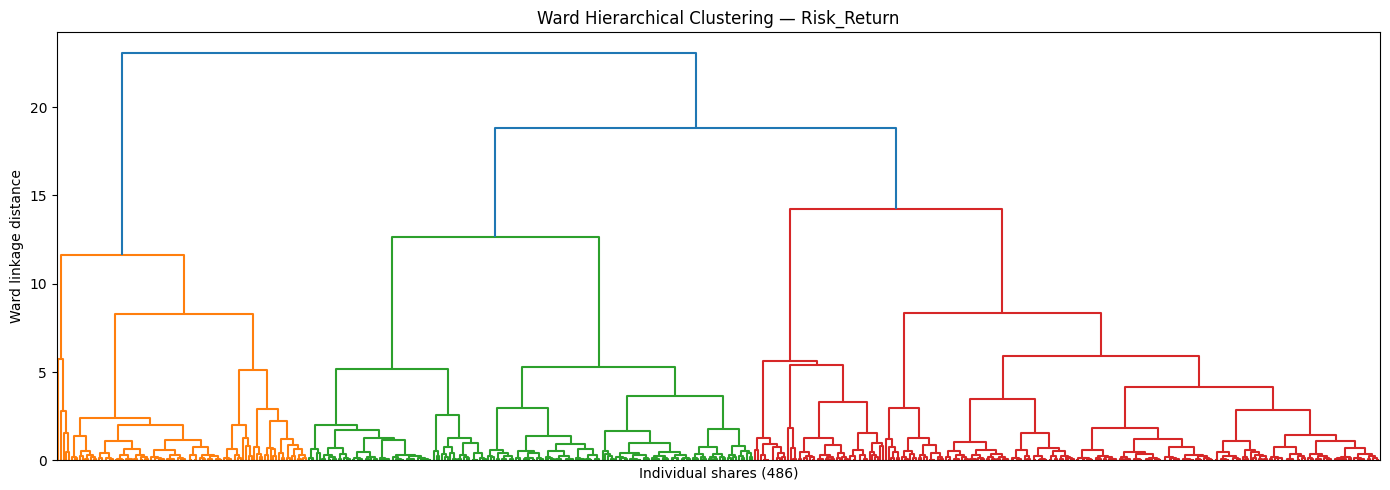

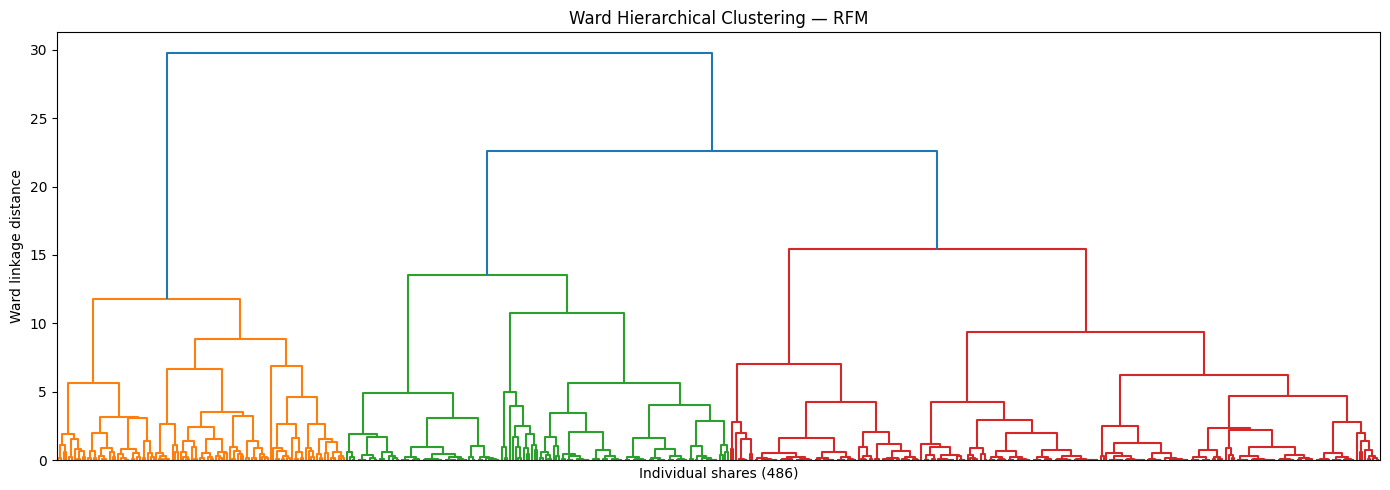

Both dendrograms saved.


In [ ]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Calculate Ward hierarchical clustering
risk_linkage = linkage(
    risk_scaled,
    method="ward",
    metric="euclidean"
)

rfm_linkage = linkage(
    rfm_scaled,
    method="ward",
    metric="euclidean"
)

# Draw one dendrogram for each feature matrix
for name, result in [
    ("Risk_Return", risk_linkage),
    ("RFM", rfm_linkage)
]:
    plt.figure(figsize=(14, 5))

    dendrogram(
        result,
        no_labels=True
    )

    plt.title(f"Ward Hierarchical Clustering — {name}")
    plt.xlabel("Individual shares (486)")
    plt.ylabel("Ward linkage distance")

    plt.tight_layout()

    plt.savefig(
        DATA_DIR / f"ward_dendrogram_{name}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("Both dendrograms saved.")


### 2.2.1 Evaluating the Number of Clusters

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

ward_results = []
ward_labels = {}

# Test both feature matrices
for name, data in [
    ("Risk-Return", risk_scaled),
    ("RFM", rfm_scaled)
]:
    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(data)

        # Save cluster assignments for later analysis
        ward_labels[(name, k)] = pd.Series(
            labels, index=data.index
        )

        # Calculate silhouette score
        silhouette = silhouette_score(data, labels)

        # Count shares per cluster
        sizes = pd.Series(labels).value_counts()

        ward_results.append({
            "Dataset": name,
            "Clusters": k,
            "Silhouette": silhouette,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Singleton_Clusters": (sizes == 1).sum()
        })

# Create evaluation table
ward_evaluation = pd.DataFrame(ward_results)

print("Risk-return cluster evaluation:")
display(
    ward_evaluation[
        ward_evaluation["Dataset"] == "Risk-Return"
    ].round(3)
)

print("\nRFM cluster evaluation:")
display(
    ward_evaluation[
        ward_evaluation["Dataset"] == "RFM"
    ].round(3)
)

# Save results
ward_evaluation.to_csv(
    DATA_DIR / "ward_cluster_evaluation.csv",
    index=False
)

Risk-return cluster evaluation:


,Dataset,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster,Singleton_Clusters
0,Risk-Return,2,0.339,92,394,0
1,Risk-Return,3,0.274,92,230,0
2,Risk-Return,4,0.282,48,182,0
3,Risk-Return,5,0.304,48,182,0
4,Risk-Return,6,0.320,5,182,0
5,Risk-Return,7,0.324,5,160,0
6,Risk-Return,8,0.321,5,160,0



RFM cluster evaluation:


,Dataset,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster,Singleton_Clusters
7,RFM,2,0.402,106,380,0
8,RFM,3,0.335,106,239,0
9,RFM,4,0.293,70,169,0
10,RFM,5,0.286,57,169,0
11,RFM,6,0.276,36,169,0
12,RFM,7,0.297,14,169,0
13,RFM,8,0.299,14,103,0


### 2.2.2 Candidate Cluster Profiles

In [ ]:
# Compare profiles of the top two silhouette candidates
for name, original in [
    ("Risk-Return", risk_raw),
    ("RFM", rfm_raw)
]:
    candidates = (
        ward_evaluation[
            ward_evaluation["Dataset"] == name
        ]
        .nlargest(2, "Silhouette")
    )

    print("\nDataset:", name)

    for k in candidates["Clusters"]:
        print("\nCandidate clusters:", k)

        profile_data = original.copy()
        profile_data["Cluster"] = ward_labels[(name, k)]

        if name == "Risk-Return":
            profile_data["Return_Pct"] = (
                profile_data["Mean_Weekly_Return"] * 100
            )
            columns = ["Return_Pct", "Weekly_Beta"]

        else:
            profile_data["Monetary_Bn"] = (
                profile_data["Monetary_USD"] / 1e9
            )
            columns = [
                "Recency_Days",
                "Frequency",
                "Monetary_Bn"
            ]

        profiles = (
            profile_data.groupby("Cluster")[columns]
            .mean()
            .round(2)
        )

        profiles.insert(
            0,
            "Shares",
            profile_data.groupby("Cluster").size()
        )

        display(profiles)



Dataset: Risk-Return

Candidate clusters: 2


,Shares,Return_Pct,Weekly_Beta
Cluster,,,
0,394,0.20,0.9
1,92,0.63,1.3



Candidate clusters: 7


,Shares,Return_Pct,Weekly_Beta
Cluster,,,
0,87,0.59,1.24
1,48,0.20,1.63
2,160,0.17,0.95
3,98,0.42,0.71
4,66,0.09,0.44
5,5,1.29,2.34
6,22,-0.16,1.14



Dataset: RFM

Candidate clusters: 2


,Shares,Recency_Days,Frequency,Monetary_Bn
Cluster,,,,
0,380,11.47,3.16,38.67
1,106,52.43,2.40,42.04



Candidate clusters: 3


,Shares,Recency_Days,Frequency,Monetary_Bn
Cluster,,,,
0,239,11.14,3.28,11.68
1,106,52.43,2.40,42.04
2,141,12.04,2.94,84.42


### 2.2.3 Selected Ward Clustering Solutions

In [ ]:
# Selected number of Ward clusters
ward_risk_k = 2
ward_rfm_k = 3

# Store the selected cluster assignments
ward_selected = pd.DataFrame({
    "Ward_Risk_Return": ward_labels[
        ("Risk-Return", ward_risk_k)
    ],
    "Ward_RFM": ward_labels[
        ("RFM", ward_rfm_k)
    ]
})

ward_selected.index.name = "Ticker"

# Risk-return cluster profiles
risk_profile = risk_raw.copy()
risk_profile["Cluster"] = ward_selected["Ward_Risk_Return"]
risk_profile["Return_Pct"] = (
    risk_profile["Mean_Weekly_Return"] * 100
)

risk_summary = risk_profile.groupby("Cluster").agg(
    Shares=("Weekly_Beta", "size"),
    Mean_Return_Pct=("Return_Pct", "mean"),
    Mean_Beta=("Weekly_Beta", "mean")
)

# RFM cluster profiles in original units
rfm_profile = rfm_raw.copy()
rfm_profile["Cluster"] = ward_selected["Ward_RFM"]
rfm_profile["Monetary_Bn"] = (
    rfm_profile["Monetary_USD"] / 1e9
)

rfm_summary = rfm_profile.groupby("Cluster").agg(
    Shares=("Recency_Days", "size"),
    Mean_Recency=("Recency_Days", "mean"),
    Mean_Frequency=("Frequency", "mean"),
    Mean_Monetary_Bn=("Monetary_Bn", "mean"),
    Median_Monetary_Bn=("Monetary_Bn", "median")
)

print("Selected Ward risk-return profiles:")
display(risk_summary.round(2))

print("\nSelected Ward RFM profiles:")
display(rfm_summary.round(2))

# Save everything
ward_selected.to_csv(
    DATA_DIR / "ward_selected_assignments.csv"
)

risk_summary.to_csv(
    DATA_DIR / "ward_risk_profiles.csv"
)

rfm_summary.to_csv(
    DATA_DIR / "ward_rfm_profiles.csv"
)

print("Selected Ward results saved.")


Selected Ward risk-return profiles:


,Shares,Mean_Return_Pct,Mean_Beta
Cluster,,,
0,394,0.20,0.9
1,92,0.63,1.3



Selected Ward RFM profiles:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_Bn,Median_Monetary_Bn
Cluster,,,,,
0,239,11.14,3.28,11.68,11.15
1,106,52.43,2.40,42.04,19.49
2,141,12.04,2.94,84.42,42.01


Selected Ward results saved.


### 2.3 K-Means Clustering

In [52]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_results = []
kmeans_labels = {}

# Evaluate both feature matrices
for name, data in [
    ("Risk-Return", risk_scaled),
    ("RFM", rfm_scaled)
]:
    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=25,
            random_state=42,
            max_iter=500
        )

        labels = model.fit_predict(data)

        kmeans_labels[(name, k)] = pd.Series(
            labels, index=data.index
        )

        sizes = pd.Series(labels).value_counts()

        kmeans_results.append({
            "Dataset": name,
            "Clusters": k,
            "Silhouette": silhouette_score(
                data, labels
            ),
            "Inertia": model.inertia_,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Singleton_Clusters": (sizes == 1).sum()
        })

kmeans_evaluation = pd.DataFrame(kmeans_results)

print("Risk-return K-Means evaluation:")
display(
    kmeans_evaluation[
        kmeans_evaluation["Dataset"] == "Risk-Return"
    ].round(3)
)

print("\nRFM K-Means evaluation:")
display(
    kmeans_evaluation[
        kmeans_evaluation["Dataset"] == "RFM"
    ].round(3)
)

kmeans_evaluation.to_csv(
    DATA_DIR / "kmeans_cluster_evaluation.csv",
    index=False
)


Risk-return K-Means evaluation:


,Dataset,Clusters,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Singleton_Clusters
0,Risk-Return,2,0.387,621.634,143,343,0
1,Risk-Return,3,0.329,461.179,119,202,0
2,Risk-Return,4,0.326,371.571,41,160,0
3,Risk-Return,5,0.338,309.960,28,165,0
4,Risk-Return,6,0.327,265.852,16,137,0
5,Risk-Return,7,0.329,227.239,5,126,0
6,Risk-Return,8,0.356,194.596,5,141,0



RFM K-Means evaluation:


,Dataset,Clusters,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Singleton_Clusters
7,RFM,2,0.415,999.520,102,384,0
8,RFM,3,0.343,742.493,90,257,0
9,RFM,4,0.362,559.244,82,194,0
10,RFM,5,0.348,480.744,40,141,0
11,RFM,6,0.345,421.187,30,139,0
12,RFM,7,0.342,378.181,19,143,0
13,RFM,8,0.338,342.209,22,131,0


In [53]:
# Examine the two highest-silhouette solutions
for name, original in [
    ("Risk-Return", risk_raw),
    ("RFM", rfm_raw)
]:
    candidates = (
        kmeans_evaluation[
            kmeans_evaluation["Dataset"] == name
        ]
        .nlargest(2, "Silhouette")
    )

    print("\nDataset:", name)

    for k in candidates["Clusters"]:
        print("\nCandidate k =", k)

        profile = original.copy()
        profile["Cluster"] = kmeans_labels[(name, k)]

        if name == "Risk-Return":
            profile["Return_Pct"] = (
                profile["Mean_Weekly_Return"] * 100
            )
            columns = ["Return_Pct", "Weekly_Beta"]
        else:
            profile["Monetary_Bn"] = (
                profile["Monetary_USD"] / 1e9
            )
            columns = [
                "Recency_Days",
                "Frequency",
                "Monetary_Bn"
            ]

        summary = (
            profile.groupby("Cluster")[columns]
            .mean()
            .round(2)
        )

        summary.insert(
            0,
            "Shares",
            profile.groupby("Cluster").size()
        )

        display(summary)


Dataset: Risk-Return

Candidate k = 2


,Shares,Return_Pct,Weekly_Beta
Cluster,,,
0,143,0.53,1.35
1,343,0.18,0.82



Candidate k = 8


,Shares,Return_Pct,Weekly_Beta
Cluster,,,
0,29,0.83,1.25
1,141,0.17,0.97
2,81,0.46,1.11
3,77,0.08,0.49
4,31,-0.13,1.32
5,43,0.31,1.63
6,79,0.40,0.63
7,5,1.29,2.34



Dataset: RFM

Candidate k = 2


,Shares,Recency_Days,Frequency,Monetary_Bn
Cluster,,,,
0,102,53.67,2.29,64.47
1,384,11.57,3.17,32.75



Candidate k = 4


,Shares,Recency_Days,Frequency,Monetary_Bn
Cluster,,,,
0,120,13.42,4.55,14.80
1,194,11.28,2.36,15.01
2,82,12.89,3.26,124.86
3,90,56.24,2.02,46.95


### 2.3.1 Selected K-Means Solutions

In [54]:
# Selected K-Means cluster counts
kmeans_risk_k = 2
kmeans_rfm_k = 2

# Save cluster assignments for the same 486 shares
kmeans_selected = pd.DataFrame({
    "KMeans_Risk_Return": kmeans_labels[
        ("Risk-Return", kmeans_risk_k)
    ],
    "KMeans_RFM": kmeans_labels[
        ("RFM", kmeans_rfm_k)
    ]
})

kmeans_selected.index.name = "Ticker"

# Risk-return profiles in original units
km_risk_profile = risk_raw.copy()
km_risk_profile["Cluster"] = (
    kmeans_selected["KMeans_Risk_Return"]
)
km_risk_profile["Return_Pct"] = (
    km_risk_profile["Mean_Weekly_Return"] * 100
)

km_risk_summary = km_risk_profile.groupby("Cluster").agg(
    Shares=("Weekly_Beta", "size"),
    Mean_Return_Pct=("Return_Pct", "mean"),
    Mean_Beta=("Weekly_Beta", "mean")
)

# RFM profiles in original units
km_rfm_profile = rfm_raw.copy()
km_rfm_profile["Cluster"] = (
    kmeans_selected["KMeans_RFM"]
)
km_rfm_profile["Monetary_Bn"] = (
    km_rfm_profile["Monetary_USD"] / 1e9
)

km_rfm_summary = km_rfm_profile.groupby("Cluster").agg(
    Shares=("Recency_Days", "size"),
    Mean_Recency=("Recency_Days", "mean"),
    Mean_Frequency=("Frequency", "mean"),
    Mean_Monetary_Bn=("Monetary_Bn", "mean"),
    Median_Monetary_Bn=("Monetary_Bn", "median")
)

print("Selected K-Means risk-return profiles:")
display(km_risk_summary.round(2))

print("\nSelected K-Means RFM profiles:")
display(km_rfm_summary.round(2))

# Save outputs
kmeans_selected.to_csv(
    DATA_DIR / "kmeans_selected_assignments.csv"
)

km_risk_summary.to_csv(
    DATA_DIR / "kmeans_risk_profiles.csv"
)

km_rfm_summary.to_csv(
    DATA_DIR / "kmeans_rfm_profiles.csv"
)

print("Selected K-Means results saved.")


Selected K-Means risk-return profiles:


,Shares,Mean_Return_Pct,Mean_Beta
Cluster,,,
0,143,0.53,1.35
1,343,0.18,0.82



Selected K-Means RFM profiles:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_Bn,Median_Monetary_Bn
Cluster,,,,,
0,102,53.67,2.29,64.47,21.18
1,384,11.57,3.17,32.75,15.26


Selected K-Means results saved.


### 2.3.2 K-Means Model Selection Charts

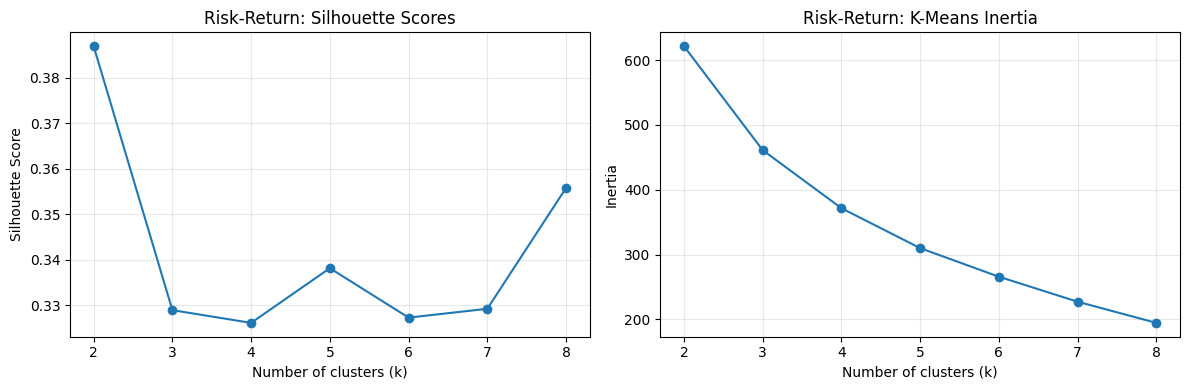

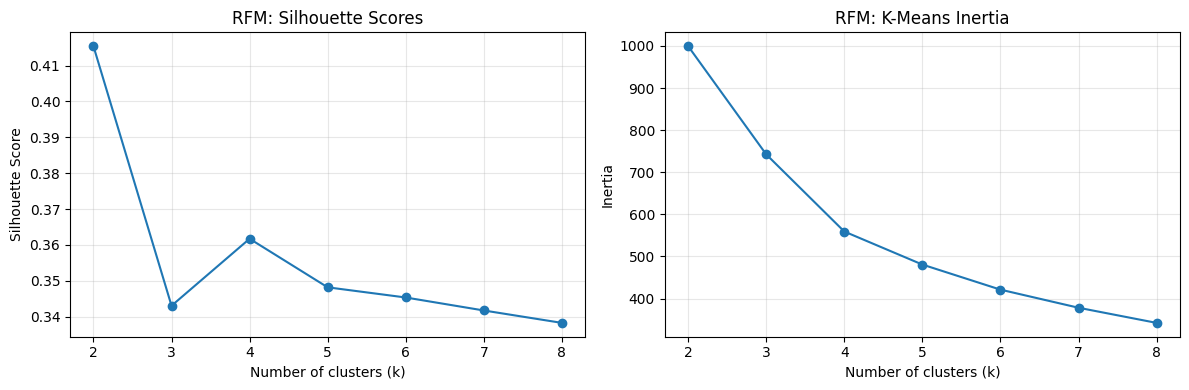

K-Means evaluation charts saved.


In [55]:
# Create evaluation charts for each dataset
for name in ["Risk-Return", "RFM"]:

    results = kmeans_evaluation[
        kmeans_evaluation["Dataset"] == name
    ].sort_values("Clusters")

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 4)
    )

    # Silhouette scores
    axes[0].plot(
        results["Clusters"],
        results["Silhouette"],
        marker="o"
    )
    axes[0].set_title(f"{name}: Silhouette Scores")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Silhouette Score")
    axes[0].set_xticks(range(2, 9))
    axes[0].grid(alpha=0.3)

    # Inertia (elbow method)
    axes[1].plot(
        results["Clusters"],
        results["Inertia"],
        marker="o"
    )
    axes[1].set_title(f"{name}: K-Means Inertia")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("Inertia")
    axes[1].set_xticks(range(2, 9))
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    filename = (
        "kmeans_evaluation_"
        + name.replace("-", "_")
        + ".png"
    )

    plt.savefig(
        DATA_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("K-Means evaluation charts saved.")


### 2.4 Cluster Membership Comparison

In [56]:
from sklearn.metrics import adjusted_rand_score

# Confirm both algorithms use identical shares
assert ward_selected.index.equals(
    kmeans_selected.index
)

# Calculate agreement between Ward and K-Means
ari_risk = adjusted_rand_score(
    ward_selected["Ward_Risk_Return"],
    kmeans_selected["KMeans_Risk_Return"]
)

ari_rfm = adjusted_rand_score(
    ward_selected["Ward_RFM"],
    kmeans_selected["KMeans_RFM"]
)

comparison_summary = pd.DataFrame({
    "Dataset": ["Risk-Return", "RFM"],
    "Ward_k": [ward_risk_k, ward_rfm_k],
    "KMeans_k": [kmeans_risk_k, kmeans_rfm_k],
    "Adjusted_Rand_Index": [ari_risk, ari_rfm]
})

print("Algorithm agreement:")
display(comparison_summary.round(3))

# Compare membership overlap
print("\nRisk-return membership comparison:")
display(pd.crosstab(
    ward_selected["Ward_Risk_Return"],
    kmeans_selected["KMeans_Risk_Return"]
))

print("\nRFM membership comparison:")
display(pd.crosstab(
    ward_selected["Ward_RFM"],
    kmeans_selected["KMeans_RFM"]
))

# Save comparison
comparison_summary.to_csv(
    DATA_DIR / "algorithm_comparison.csv",
    index=False
)

print("Algorithm comparison saved.")

Algorithm agreement:


,Dataset,Ward_k,KMeans_k,Adjusted_Rand_Index
0,Risk-Return,2,2,0.598
1,RFM,3,2,0.414



Risk-return membership comparison:


KMeans_Risk_Return,0,1
Ward_Risk_Return,,
0,51,343
1,92,0



RFM membership comparison:


KMeans_RFM,0,1
Ward_RFM,,
0,0,239
1,98,8
2,4,137


Algorithm comparison saved.


### 2.4.1 Two-Dimensional Cluster Visualisations

RFM PCA explained variance:
PC1: 43.59 %
PC2: 33.65 %
Combined: 77.24 %


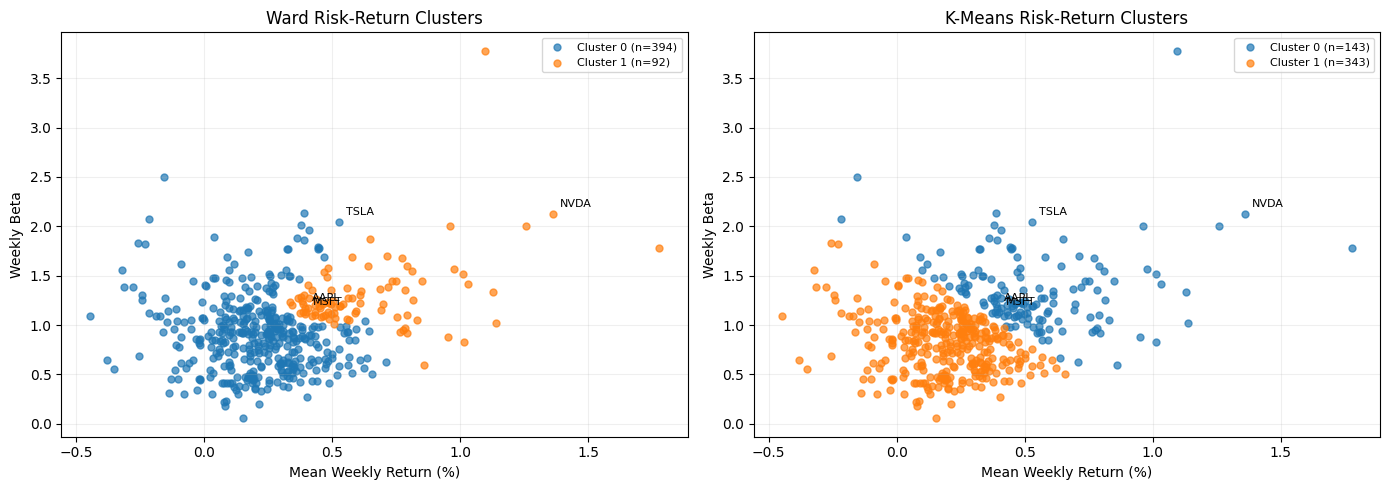

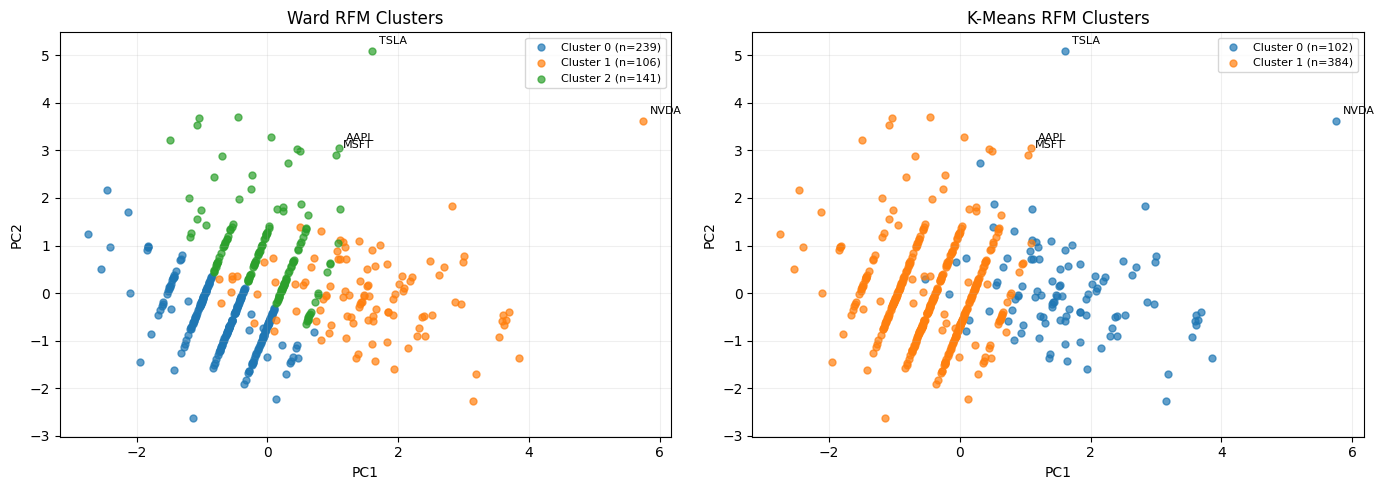

Cluster comparison figures saved.


In [57]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# PCA for displaying the three RFM features in 2D
rfm_pca = PCA(n_components=2)

rfm_coordinates = pd.DataFrame(
    rfm_pca.fit_transform(rfm_scaled),
    columns=["PC1", "PC2"],
    index=rfm_scaled.index
)

print("RFM PCA explained variance:")
print(
    "PC1:",
    round(rfm_pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)
print(
    "PC2:",
    round(rfm_pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)
print(
    "Combined:",
    round(rfm_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Reusable plotting function
def draw_cluster_plot(ax, x, y, labels, title,
                      xlabel, ylabel):

    for cluster in sorted(labels.unique()):
        mask = labels == cluster

        ax.scatter(
            x.loc[mask],
            y.loc[mask],
            s=25,
            alpha=0.7,
            label=f"Cluster {cluster} (n={mask.sum()})"
        )

    # Label a few recognisable securities
    for ticker in ["AAPL", "MSFT", "NVDA", "TSLA"]:
        if ticker in x.index:
            ax.annotate(
                ticker,
                (x.loc[ticker], y.loc[ticker]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8
            )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)


# Figure 1: Risk-return (original units)
risk_x = risk_raw["Mean_Weekly_Return"] * 100
risk_y = risk_raw["Weekly_Beta"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

draw_cluster_plot(
    axes[0], risk_x, risk_y,
    ward_selected["Ward_Risk_Return"],
    "Ward Risk-Return Clusters",
    "Mean Weekly Return (%)",
    "Weekly Beta"
)

draw_cluster_plot(
    axes[1], risk_x, risk_y,
    kmeans_selected["KMeans_Risk_Return"],
    "K-Means Risk-Return Clusters",
    "Mean Weekly Return (%)",
    "Weekly Beta"
)

plt.tight_layout()
plt.savefig(
    DATA_DIR / "risk_return_ward_vs_kmeans.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# Figure 2: RFM (PCA projection)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = rfm_coordinates["PC1"]
y = rfm_coordinates["PC2"]

draw_cluster_plot(
    axes[0], x, y,
    ward_selected["Ward_RFM"],
    "Ward RFM Clusters",
    "PC1",
    "PC2"
)

draw_cluster_plot(
    axes[1], x, y,
    kmeans_selected["KMeans_RFM"],
    "K-Means RFM Clusters",
    "PC1",
    "PC2"
)

plt.tight_layout()
plt.savefig(
    DATA_DIR / "rfm_ward_vs_kmeans_pca.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Cluster comparison figures saved.")


### 2.5.1 RFM Correlation Analysis

RFM correlation matrix:


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
Log_Monetary,0.152,0.013,1.000


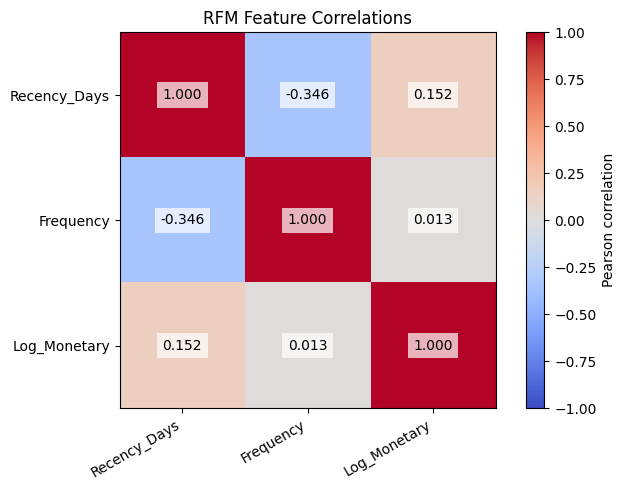

In [58]:

import numpy as np

# Use original R and F, and log-transformed M
rfm_correlation_data = pd.DataFrame({
    "Recency_Days": rfm_raw["Recency_Days"],
    "Frequency": rfm_raw["Frequency"],
    "Log_Monetary": np.log1p(
        rfm_raw["Monetary_USD"]
    )
})

# Calculate Pearson correlations
rfm_correlations = rfm_correlation_data.corr(
    method="pearson"
)

print("RFM correlation matrix:")
display(rfm_correlations.round(3))

# Create labelled correlation heatmap
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(
    rfm_correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(
    rfm_correlations.columns,
    rotation=30,
    ha="right"
)

ax.set_yticklabels(
    rfm_correlations.index
)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{rfm_correlations.iloc[i, j]:.3f}",
            ha="center",
            va="center",
            color="black",
            bbox=dict(
                facecolor="white",
                alpha=0.7,
                edgecolor="none"
            )
        )

ax.set_title("RFM Feature Correlations")
fig.colorbar(image, ax=ax, label="Pearson correlation")

plt.tight_layout()
plt.savefig(
    DATA_DIR / "rfm_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

rfm_correlations.to_csv(
    DATA_DIR / "rfm_correlations.csv"
)


### 2.5.2 Monetary Removal Sensitivity Test

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# Remove Monetary but retain the same Recency treatment
rf_only_raw = rfm_transformed[
    ["Log_Recency", "Frequency"]
].copy()

# Confirm exactly the same shares and order
assert rf_only_raw.index.equals(
    ward_selected.index
)

# Fit a NEW scaler using only the remaining features
rf_only_scaler = StandardScaler()

rf_only_scaled = pd.DataFrame(
    rf_only_scaler.fit_transform(rf_only_raw),
    index=rf_only_raw.index,
    columns=rf_only_raw.columns
)

# Refit Ward with the SAME selected k
rf_only_model = AgglomerativeClustering(
    n_clusters=ward_rfm_k,
    linkage="ward",
    metric="euclidean"
)

rf_only_labels = pd.Series(
    rf_only_model.fit_predict(rf_only_scaled),
    index=rf_only_scaled.index,
    name="Ward_RF_Without_Monetary"
)

# Compare original versus reduced Ward memberships
monetary_removal_ari = adjusted_rand_score(
    ward_selected["Ward_RFM"],
    rf_only_labels
)

print("Monetary removal sensitivity analysis")
print("Number of shares:", len(rf_only_labels))
print("Cluster count:", ward_rfm_k)
print(
    "Adjusted Rand Index:",
    round(monetary_removal_ari, 3)
)

print("\nMembership comparison:")
display(pd.crosstab(
    ward_selected["Ward_RFM"],
    rf_only_labels,
    rownames=["Original Ward RFM"],
    colnames=["Ward Without Monetary"]
))

# Compare profiles using ORIGINAL RFM values
def create_rfm_profile(labels):

    profile = rfm_raw.copy()
    profile["Cluster"] = labels
    profile["Monetary_Bn"] = (
        profile["Monetary_USD"] / 1e9
    )

    return profile.groupby("Cluster").agg(
        Shares=("Recency_Days", "size"),
        Mean_Recency=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary_Bn=("Monetary_Bn", "mean"),
        Median_Monetary_Bn=("Monetary_Bn", "median")
    )

original_rfm_profiles = create_rfm_profile(
    ward_selected["Ward_RFM"]
)

reduced_rf_profiles = create_rfm_profile(
    rf_only_labels
)

print("\nOriginal Ward RFM profiles:")
display(original_rfm_profiles.round(2))

print("\nWard profiles WITHOUT Monetary:")
display(reduced_rf_profiles.round(2))

# Save membership comparison
sensitivity_assignments = pd.DataFrame({
    "Original_Ward_RFM": ward_selected["Ward_RFM"],
    "Ward_Without_Monetary": rf_only_labels
})

sensitivity_assignments.to_csv(
    DATA_DIR / "ward_monetary_sensitivity_assignments.csv"
)

# Save original-unit cluster profiles
sensitivity_profiles = pd.concat(
    {
        "Original_RFM": original_rfm_profiles,
        "Without_Monetary": reduced_rf_profiles
    },
    names=["Model", "Cluster"]
)

sensitivity_profiles.to_csv(
    DATA_DIR / "ward_monetary_sensitivity_profiles.csv"
)

print("\nSensitivity results saved.")


Monetary removal sensitivity analysis
Number of shares: 486
Cluster count: 3
Adjusted Rand Index: 0.349

Membership comparison:


Ward Without Monetary,0,1,2
Original Ward RFM,,,
0,0,173,66
1,101,5,0
2,8,74,59



Original Ward RFM profiles:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_Bn,Median_Monetary_Bn
Cluster,,,,,
0,239,11.14,3.28,11.68,11.15
1,106,52.43,2.40,42.04,19.49
2,141,12.04,2.94,84.42,42.01



Ward profiles WITHOUT Monetary:


,Shares,Mean_Recency,Mean_Frequency,Mean_Monetary_Bn,Median_Monetary_Bn
Cluster,,,,,
0,109,51.72,2.53,66.94,20.85
1,252,11.51,3.78,30.01,14.74
2,125,11.04,1.80,34.34,17.70



Sensitivity results saved.


### Task 2 Final Verification — PCA Explained Variance

In [61]:
print("RFM PCA explained variance")

for i, variance in enumerate(
    rfm_pca.explained_variance_ratio_,
    start=1
):
    print(f"PC{i}: {variance * 100:.2f}%")

print(
    "Total variance explained:",
    f"{rfm_pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


RFM PCA explained variance
PC1: 43.59%
PC2: 33.65%
Total variance explained: 77.24%


In [62]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/CRM_CWK1_backup",
    "zip",
    "/content/CRM_CWK1"
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 3 — Business Intelligence and Critical Review

### 3.2.1 Cluster Profiles and Sector Composition

In [64]:
import pandas as pd
import numpy as np
from pathlib import Path

# Restore company metadata if it is not in memory
if "companies" not in globals():
    companies = pd.read_csv(
        DATA_DIR / "sp500_tickers.csv"
    )

# Extract company and sector information
share_metadata = companies[
    ["YahooTicker", "Security", "GICS Sector"]
].rename(
    columns={
        "YahooTicker": "Ticker",
        "GICS Sector": "Sector"
    }
)

# Confirm unique ticker records
assert share_metadata["Ticker"].is_unique

share_metadata = share_metadata.set_index("Ticker")

# Begin with the final Task 1 features
analysis_mart = final_features.set_index(
    "Ticker"
).copy()

# Add security and sector information
analysis_mart = analysis_mart.join(
    share_metadata,
    how="left"
)

# Add Ward and K-Means assignments
analysis_mart = analysis_mart.join(
    ward_selected,
    how="left"
)

analysis_mart = analysis_mart.join(
    kmeans_selected,
    how="left"
)

# Add the Monetary-removal sensitivity model
analysis_mart["Ward_RF_Without_Monetary"] = (
    rf_only_labels
)

# Validate the consolidated dataset
assert len(analysis_mart) == 486
assert analysis_mart.index.is_unique
assert analysis_mart["Sector"].notna().all()

cluster_columns = [
    "Ward_Risk_Return",
    "Ward_RFM",
    "KMeans_Risk_Return",
    "KMeans_RFM",
    "Ward_RF_Without_Monetary"
]

assert not analysis_mart[
    cluster_columns
].isna().any().any()

print("TASK 3 ANALYSIS DATASET")
print("-----------------------")
print("Number of shares:", len(analysis_mart))
print("Number of sectors:",
      analysis_mart["Sector"].nunique())

print("\nSector distribution:")
display(
    analysis_mart["Sector"]
    .value_counts()
    .rename("Shares")
)

print("\nAnalysis dataset preview:")
display(
    analysis_mart[
        ["Security", "Sector"] + cluster_columns
    ].head()
)

# Save dataset
analysis_mart.to_csv(
    DATA_DIR / "task3_analysis_mart.csv"
)

print("\nTask 3 dataset saved.")

TASK 3 ANALYSIS DATASET
-----------------------
Number of shares: 486
Number of sectors: 11

Sector distribution:


,Shares
Sector,
Industrials,78
Financials,74
Information Technology,74
Health Care,58
Consumer Discretionary,47
Consumer Staples,32
Utilities,30
Real Estate,30
Materials,23



Analysis dataset preview:


,Security,Sector,Ward_Risk_Return,Ward_RFM,KMeans_Risk_Return,KMeans_RFM,Ward_RF_Without_Monetary
Ticker,,,,,,,
A,Agilent Technologies,Health Care,0,0,1,1,2
AAPL,Apple Inc.,Information Technology,1,2,0,1,2
ABBV,AbbVie,Health Care,0,2,1,1,1
ABNB,Airbnb,Consumer Discretionary,0,2,0,1,1
ABT,Abbott Laboratories,Health Care,0,2,1,1,2



Task 3 dataset saved.


### 3.2.1.1 Sector Composition Analysis

In [67]:
# Analyse sector composition for all four baseline models
models = {
    "Ward_Risk_Return": "Ward Risk-Return",
    "Ward_RFM": "Ward RFM",
    "KMeans_Risk_Return": "K-Means Risk-Return",
    "KMeans_RFM": "K-Means RFM"
}

sector_counts = {}
sector_percentages = {}

for column, name in models.items():

    # Number of shares in each sector and cluster
    counts = pd.crosstab(
        analysis_mart["Sector"],
        analysis_mart[column]
    )

    # Percentage of each sector assigned to each cluster
    percentages = (
        counts.div(
            counts.sum(axis=1),
            axis=0
        ) * 100
    )

    sector_counts[column] = counts
    sector_percentages[column] = percentages

    print("\n", name)
    print("Number of shares:")
    display(counts)

    print("Percentage within each sector:")
    display(percentages.round(1))

    # Save the tables
    counts.to_csv(
        DATA_DIR / f"sector_counts_{column}.csv"
    )

    percentages.to_csv(
        DATA_DIR / f"sector_percentages_{column}.csv"
    )

print("\nAll sector composition tables saved.")


 Ward Risk-Return
Number of shares:


Ward_Risk_Return,0,1
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


Percentage within each sector:


Ward_Risk_Return,0,1
Sector,,
Communication Services,75.0,25.0
Consumer Discretionary,76.6,23.4
Consumer Staples,100.0,0.0
Energy,80.0,20.0
Financials,82.4,17.6
Health Care,96.6,3.4
Industrials,73.1,26.9
Information Technology,60.8,39.2
Materials,87.0,13.0



 Ward RFM
Number of shares:


Ward_RFM,0,1,2
Sector,,,
Communication Services,7,4,9
Consumer Discretionary,18,12,17
Consumer Staples,14,8,10
Energy,7,3,10
Financials,38,15,21
Health Care,26,11,21
Industrials,48,11,19
Information Technology,22,24,28
Materials,13,8,2


... (7 outputs left out)

KMeans_RFM,0,1
Sector,,
Communication Services,3,17
Consumer Discretionary,13,34
Consumer Staples,8,24
Energy,3,17
Financials,13,61
Health Care,9,49
Industrials,11,67
Information Technology,25,49
Materials,8,15


Percentage within each sector:


KMeans_RFM,0,1
Sector,,
Communication Services,15.0,85.0
Consumer Discretionary,27.7,72.3
Consumer Staples,25.0,75.0
Energy,15.0,85.0
Financials,17.6,82.4
Health Care,15.5,84.5
Industrials,14.1,85.9
Information Technology,33.8,66.2
Materials,34.8,65.2



All sector composition tables saved.


### 3.2.1.2 Sector Composition Visualisations

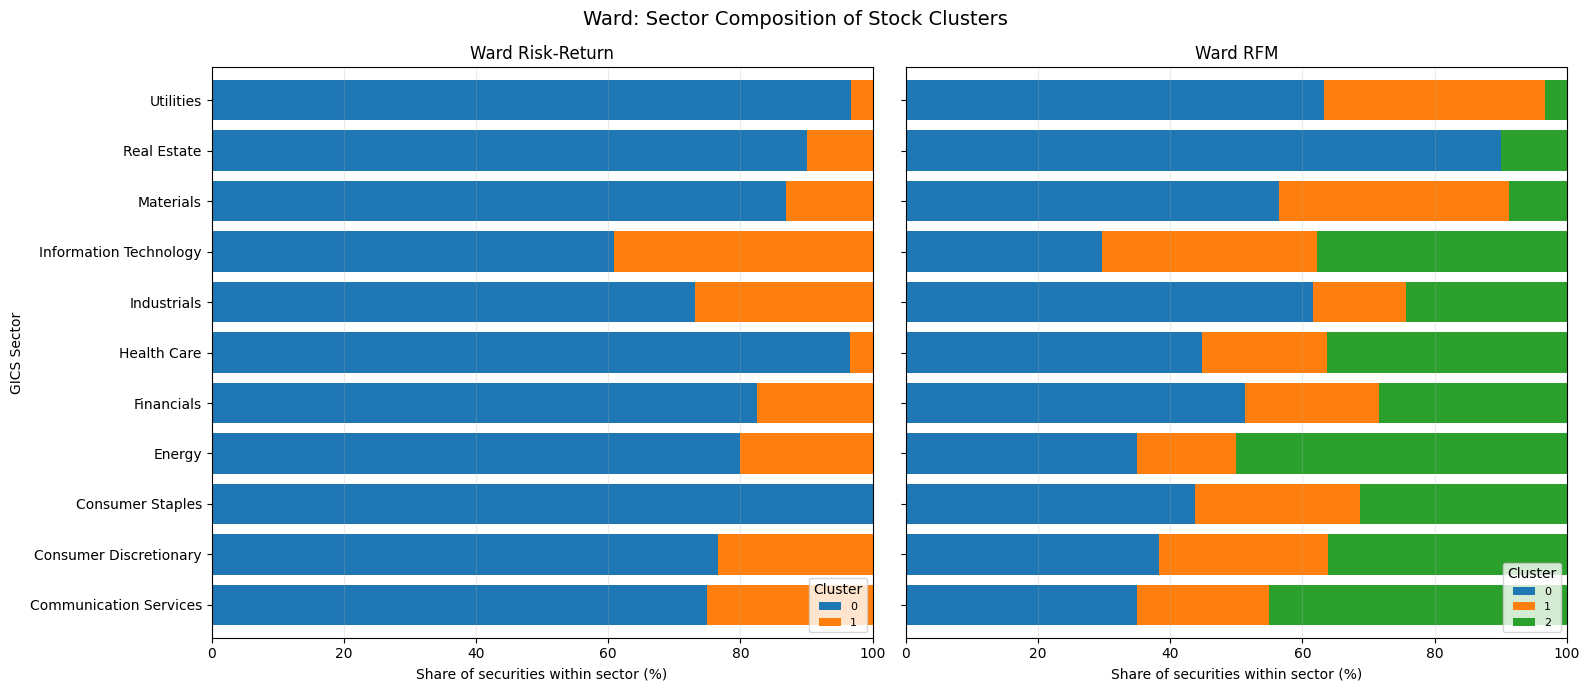

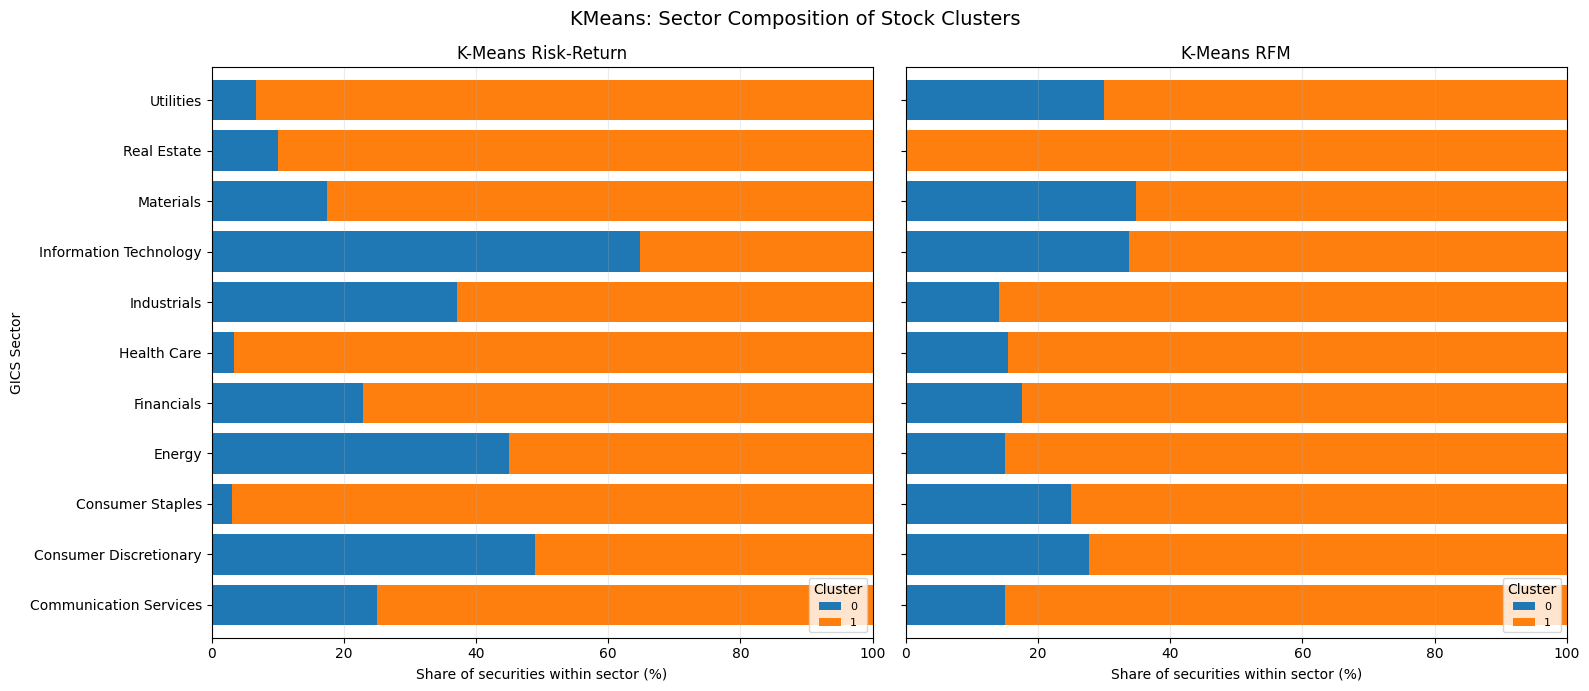

Sector composition figures saved.


In [68]:
import matplotlib.pyplot as plt

# Make a comparison chart for each algorithm
for algorithm, columns in [
    ("Ward", ["Ward_Risk_Return", "Ward_RFM"]),
    ("KMeans", ["KMeans_Risk_Return", "KMeans_RFM"])
]:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 7),
        sharey=True
    )

    for ax, column in zip(axes, columns):

        percentages = sector_percentages[column]

        percentages.plot(
            kind="barh",
            stacked=True,
            ax=ax,
            width=0.8
        )

        ax.set_title(models[column])
        ax.set_xlabel("Share of securities within sector (%)")
        ax.set_ylabel("GICS Sector")

        ax.set_xlim(0, 100)
        ax.legend(
            title="Cluster",
            loc="lower right",
            fontsize=8
        )

        ax.grid(
            axis="x",
            alpha=0.25
        )

    plt.suptitle(
        f"{algorithm}: Sector Composition of Stock Clusters",
        fontsize=14
    )

    plt.tight_layout()

    filename = (
        f"task3_sector_composition_{algorithm}.png"
    )

    plt.savefig(
        DATA_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

print("Sector composition figures saved.")

### 3.2.1.3 Cross-Cluster and Sector Composition Analysis

In [69]:
import pandas as pd

# Part A: Compare Ward risk-return and Ward RFM assignments
cross_cluster = pd.crosstab(
    analysis_mart["Ward_Risk_Return"],
    analysis_mart["Ward_RFM"]
)

cross_cluster_pct = pd.crosstab(
    analysis_mart["Ward_Risk_Return"],
    analysis_mart["Ward_RFM"],
    normalize="index"
) * 100

print("WARD RISK-RETURN VS WARD RFM")
print("\nNumber of shares:")
display(cross_cluster)

print("\nPercentage within each risk-return cluster:")
display(cross_cluster_pct.round(1))


# Part B: Compare original-unit feature profiles
cross_profiles = analysis_mart.groupby(
    "Ward_RFM"
).agg(
    Shares=("Weekly_Beta", "size"),
    Mean_Weekly_Return=(
        "Mean_Weekly_Return", "mean"
    ),
    Mean_Beta=("Weekly_Beta", "mean"),
    Mean_Recency=("Recency_Days", "mean"),
    Mean_Frequency=("Frequency", "mean"),
    Median_Monetary=("Monetary_USD", "median")
)

cross_profiles["Mean_Weekly_Return"] *= 100
cross_profiles["Median_Monetary"] /= 1e9

cross_profiles = cross_profiles.rename(
    columns={
        "Mean_Weekly_Return": "Mean_Return_Pct",
        "Median_Monetary": "Median_Monetary_Bn"
    }
)

print("\nRFM CLUSTER PROFILES INCLUDING RISK-RETURN:")
display(cross_profiles.round(2))


# Part C: Inspect sector composition WITHIN key clusters
focus_groups = {
    "Ward higher-return/beta": (
        "Ward_Risk_Return", 1
    ),
    "Ward recent/higher-value RFM": (
        "Ward_RFM", 2
    ),
    "K-Means higher-return/beta": (
        "KMeans_Risk_Return", 0
    ),
    "K-Means less-recent RFM": (
        "KMeans_RFM", 0
    )
}

focus_rows = []

for group_name, (column, cluster_id) in focus_groups.items():

    subset = analysis_mart[
        analysis_mart[column] == cluster_id
    ]

    sector_counts_here = (
        subset["Sector"].value_counts()
    )

    for sector, count in sector_counts_here.items():

        focus_rows.append({
            "Group": group_name,
            "Sector": sector,
            "Shares": int(count),
            "Pct_Of_Cluster": (
                count / len(subset) * 100
            )
        })

focus_summary = pd.DataFrame(focus_rows)

print("\nTOP FIVE SECTORS WITHIN EACH SELECTED CLUSTER:")

for group_name in focus_groups:

    print("\n", group_name)

    display(
        focus_summary[
            focus_summary["Group"] == group_name
        ].nlargest(5, "Shares").round(1)
    )


# Save the outputs
cross_cluster.to_csv(
    DATA_DIR / "task3_cross_cluster_counts.csv"
)

cross_cluster_pct.to_csv(
    DATA_DIR / "task3_cross_cluster_percentages.csv"
)

cross_profiles.to_csv(
    DATA_DIR / "task3_cross_cluster_profiles.csv"
)

focus_summary.to_csv(
    DATA_DIR / "task3_sector_composition_within_clusters.csv",
    index=False
)

assert cross_cluster.to_numpy().sum() == 486

print("\nTask 3 cross-cluster analysis saved.")


WARD RISK-RETURN VS WARD RFM

Number of shares:


Ward_RFM,0,1,2
Ward_Risk_Return,,,
0,207,81,106
1,32,25,35



Percentage within each risk-return cluster:


Ward_RFM,0,1,2
Ward_Risk_Return,,,
0,52.5,20.6,26.9
1,34.8,27.2,38.0



RFM CLUSTER PROFILES INCLUDING RISK-RETURN:


,Shares,Mean_Return_Pct,Mean_Beta,Mean_Recency,Mean_Frequency,Median_Monetary_Bn
Ward_RFM,,,,,,
0,239,0.25,0.93,11.14,3.28,11.15
1,106,0.30,1.03,52.43,2.40,19.49
2,141,0.34,1.01,12.04,2.94,42.01


... (5 outputs left out)

,Group,Sector,Shares,Pct_Of_Cluster
21,K-Means higher-return/beta,Information Technology,48,33.6
22,K-Means higher-return/beta,Industrials,29,20.3
23,K-Means higher-return/beta,Consumer Discretionary,23,16.1
24,K-Means higher-return/beta,Financials,17,11.9
25,K-Means higher-return/beta,Energy,9,6.3



 K-Means less-recent RFM


,Group,Sector,Shares,Pct_Of_Cluster
32,K-Means less-recent RFM,Information Technology,25,24.5
33,K-Means less-recent RFM,Financials,13,12.7
34,K-Means less-recent RFM,Consumer Discretionary,13,12.7
35,K-Means less-recent RFM,Industrials,11,10.8
36,K-Means less-recent RFM,Utilities,9,8.8



Task 3 cross-cluster analysis saved.


In [70]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/CRM_CWK1_backup",
    "zip",
    "/content/CRM_CWK1"
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>